Nama: Emery Fathan Zwageri
NIM: 13522079
Model yang Dievaluasi: Faster R-CNN
Task: Object Detection
Dataset: COCO-1000
Detail Tugas Anda
Apa yang Anda evaluasi: - Model Faster R-CNN adalah two-stage detector (berbeda paradigma dari YOLO) - Architecture: menggunakan Region Proposal Network (RPN) + classification head - Parameter: 41.3 juta, ukuran lebih besar - Kecepatan inference: 120-150 ms per gambar (lebih lambat) - Akurasi baseline: sekitar 82-85% (lebih akurat dari YOLO!)
Dataset yang digunakan: - COCO-1000
Fokus penelitian Anda: Membandingkan strategi deteksi yang berbeda: single-stage (YOLO) vs
two-stage (Faster R-CNN). Pertanyaan utama Anda:
1. Berapa besar peningkatan akurasi dengan two-stage?
2. Apakah peningkatan akurasi worth dengan 3x lebih lambat?
3. Pada kesulitan apa two-stage lebih baik?
4. Bagaimana precision bounding box (IoU) antara kedua paradigma?
Analisis khusus untuk Anda: - Fokus pada presisi lokalisasi bounding box - Analisis: distribusi IoU (Intersection over Union) dari semua detections - Bandingkan: berapa persen detections dengan IoU > 0.5, > 0.7, > 0.9 - Insight yang dicari: "Two-stage detectors memberikan bounding box lebih presisi"

In [1]:
# Install dependencies
!pip install -q transformers torch torchvision pillow matplotlib datasets ultralytics tqdm pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 38.1 MB/s eta 0:00:00


# 1. Streaming Dataset(karena tidak bisa mendownload 1000 saja kecuali mendownload full lalu mengambil 1000)

In [2]:
from datasets import load_dataset

coco = load_dataset('detection-datasets/coco', split='val', streaming=True)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md:   0%|          | 0.00/58.0 [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/40 [00:00<?, ?it/s]

dataset_infos.json: 0.00B [00:00, ?B/s]

In [3]:
contoh_data = next(iter(coco))
print(contoh_data)

{'image_id': 139, 'image': <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=640x426 at 0x7F9018F42F00>, 'width': 640, 'height': 426, 'objects': {'bbox_id': [26547, 34646, 35802, 103487, 104368, 105328, 110334, 230831, 233201, 1640282, 1647285, 1648594, 1654394, 1666628, 1667817, 1669970, 1941808, 2146194, 2146548, 2204286], 'category': [58, 62, 62, 56, 56, 56, 56, 0, 0, 68, 72, 73, 73, 74, 75, 75, 56, 75, 75, 60], 'bbox': [[236.98, 142.51, 261.68, 212.01], [7.03, 167.76, 156.35, 262.63], [557.21, 209.19, 638.5600000000001, 287.92], [358.98, 218.05, 414.98, 320.88], [290.69, 218.0, 352.52, 316.48], [413.2, 223.01, 443.37, 304.37], [317.4, 219.24, 338.97999999999996, 230.83], [412.8, 157.61, 465.85, 295.62], [384.43, 172.21, 399.55, 207.95000000000002], [512.22, 205.75, 526.96, 221.72], [493.1, 174.34, 513.39, 282.65], [604.77, 305.89, 619.11, 351.59999999999997], [613.24, 308.24, 626.12, 354.68], [447.77, 121.12, 461.74, 143.0], [549.06, 309.43, 585.7399999999999, 399.1], [350.76,

Simpan pada list 1000 gambar pertama agar gampang diiterasi

In [4]:
coco_list = list(coco.take(1000))

In [5]:

num_samples = 5
for idx, sample in enumerate(coco.take(num_samples)):
    print(f"\n=== Sample {idx + 1} ===")
    print(f"Image ID: {sample.get('image_id', 'N/A')}")
    print(f"Image size: {sample['image'].size}")
    print(f"Number of objects: {len(sample['objects']['category'])}")
    print(f"Categories: {sample['objects']['category'][:5]}")  # Show first 5 categories


=== Sample 1 ===
Image ID: 139
Image size: (640, 426)
Number of objects: 20
Categories: [58, 62, 62, 56, 56]

=== Sample 2 ===
Image ID: 285
Image size: (586, 640)
Number of objects: 1
Categories: [21]

=== Sample 3 ===
Image ID: 632
Image size: (640, 483)
Number of objects: 18
Categories: [59, 58, 73, 73, 73]

=== Sample 4 ===
Image ID: 724
Image size: (375, 500)
Number of objects: 4
Categories: [11, 7, 2, 11]

=== Sample 5 ===
Image ID: 776
Image size: (428, 640)
Number of objects: 4
Categories: [77, 77, 77, 59]


# 2. Visualisasi beberapa sampel dataset

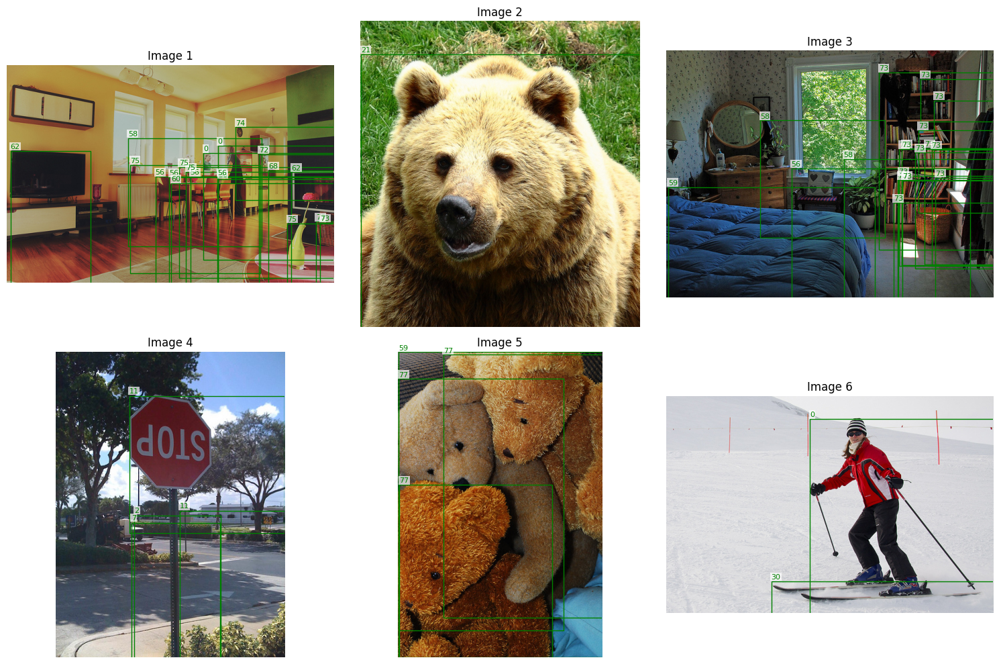

In [6]:

import matplotlib.pyplot as plt
import matplotlib.patches as patches

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for idx, sample in enumerate(coco.take(6)):
    ax = axes[idx]
    image = sample['image']
    ax.imshow(image)

    # Gambar bounding boxes dari ground truth
    for bbox, category in zip(sample['objects']['bbox'], sample['objects']['category']):
        x, y, w, h = bbox
        rect = patches.Rectangle((x, y), w, h, linewidth=1,
                                edgecolor='green', facecolor='none')
        ax.add_patch(rect)
        ax.text(x, y-5, str(category), color='green', fontsize=8,
                bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=1))

    ax.set_title(f"Image {idx + 1}")
    ax.axis('off')

plt.tight_layout()
plt.show()

# 3. Setup: Faster R-CNN vs YOLO Comparison

In [7]:
import torch
import torchvision
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2, FasterRCNN_ResNet50_FPN_V2_Weights
from ultralytics import YOLO
import numpy as np
import pandas as pd
import json
from datetime import datetime
from tqdm import tqdm
import time
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from collections import defaultdict

# Check device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# Configuration
CONFIDENCE_THRESHOLD = 0.5  # Same threshold for fair comparison
DATASET_NAME = "COCO-1000"

# COCO class mapping (91 classes including background)
COCO_CLASSES = {
    1: 'person', 2: 'bicycle', 3: 'car', 4: 'motorcycle', 5: 'airplane',
    6: 'bus', 7: 'train', 8: 'truck', 9: 'boat', 10: 'traffic light',
    11: 'fire hydrant', 13: 'stop sign', 14: 'parking meter', 15: 'bench',
    16: 'bird', 17: 'cat', 18: 'dog', 19: 'horse', 20: 'sheep',
    21: 'cow', 22: 'elephant', 23: 'bear', 24: 'zebra', 25: 'giraffe',
    27: 'backpack', 28: 'umbrella', 31: 'handbag', 32: 'tie', 33: 'suitcase',
    34: 'frisbee', 35: 'skis', 36: 'snowboard', 37: 'sports ball', 38: 'kite',
    39: 'baseball bat', 40: 'baseball glove', 41: 'skateboard', 42: 'surfboard',
    43: 'tennis racket', 44: 'bottle', 46: 'wine glass', 47: 'cup', 48: 'fork',
    49: 'knife', 50: 'spoon', 51: 'bowl', 52: 'banana', 53: 'apple',
    54: 'sandwich', 55: 'orange', 56: 'broccoli', 57: 'carrot', 58: 'hot dog',
    59: 'pizza', 60: 'donut', 61: 'cake', 62: 'chair', 63: 'couch',
    64: 'potted plant', 65: 'bed', 67: 'dining table', 70: 'toilet', 72: 'tv',
    73: 'laptop', 74: 'mouse', 75: 'remote', 76: 'keyboard', 77: 'cell phone',
    78: 'microwave', 79: 'oven', 80: 'toaster', 81: 'sink', 82: 'refrigerator',
    84: 'book', 85: 'clock', 86: 'vase', 87: 'scissors', 88: 'teddy bear',
    89: 'hair drier', 90: 'toothbrush'
}

print("✅ Configuration loaded!")

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Using device: cuda
✅ Configuration loaded!


In [8]:
# IoU Calculation Functions
def calculate_iou(box1, box2):
    """
    Calculate IoU between two boxes.
    box format: [x1, y1, x2, y2] (corner format)
    """
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection = max(0, x2 - x1) * max(0, y2 - y1)

    area1 = (box1[2] - box1[0]) * (box1[3] - box1[1])
    area2 = (box2[2] - box2[0]) * (box2[3] - box2[1])

    union = area1 + area2 - intersection

    if union == 0:
        return 0

    return intersection / union

def convert_xywh_to_xyxy(bbox):
    """Convert [x, y, w, h] to [x1, y1, x2, y2]"""
    x, y, w, h = bbox
    return [x, y, x + w, y + h]

# YOLO to COCO class mapping (YOLO uses 0-79, COCO GT uses 1-90)
YOLO_TO_COCO = {
    0: 1, 1: 2, 2: 3, 3: 4, 4: 5, 5: 6, 6: 7, 7: 8, 8: 9, 9: 10,
    10: 11, 11: 13, 12: 14, 13: 15, 14: 16, 15: 17, 16: 18, 17: 19, 18: 20, 19: 21,
    20: 22, 21: 23, 22: 24, 23: 25, 24: 27, 25: 28, 26: 31, 27: 32, 28: 33, 29: 34,
    30: 35, 31: 36, 32: 37, 33: 38, 34: 39, 35: 40, 36: 41, 37: 42, 38: 43, 39: 44,
    40: 46, 41: 47, 42: 48, 43: 49, 44: 50, 45: 51, 46: 52, 47: 53, 48: 54, 49: 55,
    50: 56, 51: 57, 52: 58, 53: 59, 54: 60, 55: 61, 56: 62, 57: 63, 58: 64, 59: 65,
    60: 67, 61: 70, 62: 72, 63: 73, 64: 74, 65: 75, 66: 76, 67: 77, 68: 78, 69: 79,
    70: 80, 71: 81, 72: 82, 73: 84, 74: 85, 75: 86, 76: 87, 77: 88, 78: 89, 79: 90
}

def match_predictions_to_gt(pred_boxes, pred_labels, gt_boxes, gt_labels, iou_threshold=0.5, class_agnostic=False):
    """
    Match predictions to ground truth and calculate IoU for matched pairs.
    FIXED VERSION: Returns matched_pred_boxes untuk kategorisasi size yang benar.

    Returns:
        matched_ious: list of IoUs for true positive matches
        matched_pred_boxes: list of prediction boxes yang benar-benar match
        tp: number of true positives
        fn: number of false negatives
    """
    if len(pred_boxes) == 0 or len(gt_boxes) == 0:
        return [], [], 0, len(gt_boxes)  # ious, matched_boxes, tp, fn

    matched_ious = []
    matched_pred_boxes = []  # Track which pred box was matched - FIX!
    matched_gt = set()
    tp = 0

    for pred_idx, (pred_box, pred_label) in enumerate(zip(pred_boxes, pred_labels)):
        best_iou = 0
        best_gt_idx = -1

        for gt_idx, (gt_box, gt_label) in enumerate(zip(gt_boxes, gt_labels)):
            if gt_idx in matched_gt:
                continue

            # Class matching (jika tidak class_agnostic)
            if not class_agnostic:
                if int(pred_label) != int(gt_label):
                    continue

            iou = calculate_iou(pred_box, gt_box)
            if iou > best_iou:
                best_iou = iou
                best_gt_idx = gt_idx

        if best_iou >= iou_threshold and best_gt_idx != -1:
            matched_ious.append(best_iou)
            matched_pred_boxes.append(pred_box)  # Simpan box yang BENAR-BENAR match
            matched_gt.add(best_gt_idx)
            tp += 1

    fn = len(gt_boxes) - len(matched_gt)

    return matched_ious, matched_pred_boxes, tp, fn

def get_object_size_category(box):
    """Categorize object by size (COCO standard: small < 32^2, medium < 96^2, large >= 96^2)"""
    area = (box[2] - box[0]) * (box[3] - box[1])
    if area < 32*32:
        return 'small'
    elif area < 96*96:
        return 'medium'
    else:
        return 'large'

print("✅ IoU functions defined (FIXED VERSION)")
print("   - Returns: matched_ious, matched_pred_boxes, tp, fn")
print("   - matched_pred_boxes untuk size categorization yang benar")

✅ IoU functions defined (FIXED VERSION)
   - Returns: matched_ious, matched_pred_boxes, tp, fn
   - matched_pred_boxes untuk size categorization yang benar


# 4. Run Inference: Faster R-CNN (Two-Stage)

In [9]:
# Load Models
print("Loading Faster R-CNN (Two-Stage Detector)...")
weights = FasterRCNN_ResNet50_FPN_V2_Weights.COCO_V1
frcnn_model = fasterrcnn_resnet50_fpn_v2(weights=weights)
frcnn_model.to(device)
frcnn_model.eval()
print(f"✅ Faster R-CNN loaded! Parameters: {sum(p.numel() for p in frcnn_model.parameters())/1e6:.1f}M")

print("\nLoading YOLOv8 (Single-Stage Detector)...")
yolo_model = YOLO('yolov8m.pt')
print(f"✅ YOLOv8 loaded!")

Loading Faster R-CNN (Two-Stage Detector)...
Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth


100%|██████████| 167M/167M [00:00<00:00, 176MB/s]


✅ Faster R-CNN loaded! Parameters: 43.7M

Loading YOLOv8 (Single-Stage Detector)...
✅ YOLOv8 loaded!


In [10]:
# Faster R-CNN Inference (CLASS-AGNOSTIC - Focus on Bounding Box Only)
from torchvision import transforms

frcnn_results = []
frcnn_all_ious = []
frcnn_ious_by_size = {'small': [], 'medium': [], 'large': []}
frcnn_inference_times = []

transform = transforms.ToTensor()

print(f"Running Faster R-CNN on {len(coco_list)} images...")
print("Mode: CLASS-AGNOSTIC (Bounding Box Precision Only)")
print("=" * 60)

for idx, sample in enumerate(tqdm(coco_list, desc="Faster R-CNN")):
    image = sample['image'].convert('RGB')

    # Get ground truth
    gt_bboxes_xywh = sample['objects']['bbox']
    gt_labels_raw = sample['objects']['category']
    gt_bboxes = [convert_xywh_to_xyxy(bb) for bb in gt_bboxes_xywh]
    gt_labels = [YOLO_TO_COCO[int(c)] for c in gt_labels_raw]

    # Preprocess
    image_tensor = transform(image).to(device)

    # Inference with timing
    start_time = time.time()
    with torch.no_grad():
        outputs = frcnn_model([image_tensor])
    inference_time = time.time() - start_time
    frcnn_inference_times.append(inference_time)

    # Filter by confidence
    pred_boxes = outputs[0]['boxes'].cpu().numpy()
    pred_scores = outputs[0]['scores'].cpu().numpy()
    pred_labels = outputs[0]['labels'].cpu().numpy()

    mask = pred_scores >= CONFIDENCE_THRESHOLD
    pred_boxes = pred_boxes[mask]
    pred_scores = pred_scores[mask]
    pred_labels = pred_labels[mask]

    if len(pred_scores) > 0:
      order = np.argsort(-pred_scores)
      pred_boxes  = pred_boxes[order]
      pred_scores = pred_scores[order]
      pred_labels = pred_labels[order]
    TOPK = 50   # atau 100, pilih satu dan konsisten
    pred_boxes  = pred_boxes[:TOPK]
    pred_scores = pred_scores[:TOPK]
    pred_labels = pred_labels[:TOPK]

    # Calculate IoUs - FIXED: now returns 4 values
    matched_ious, matched_pred_boxes, tp, fn = match_predictions_to_gt(
        pred_boxes.tolist(), pred_labels.tolist(),
        gt_bboxes, gt_labels,
        iou_threshold=0.5,
        class_agnostic=True
    )

    frcnn_all_ious.extend(matched_ious)

    # Categorize by object size using matched_pred_boxes
    for iou, pred_box in zip(matched_ious, matched_pred_boxes):
        size_cat = get_object_size_category(pred_box)
        frcnn_ious_by_size[size_cat].append(iou)

    frcnn_results.append({
        'image_id': idx,
        'num_gt': len(gt_bboxes),
        'num_detections': len(pred_boxes),
        'tp': tp,
        'fn': fn,
        'fp': max(0, len(pred_boxes) - tp),
        'avg_confidence': float(pred_scores.mean()) if len(pred_scores) > 0 else 0,
        'avg_iou': float(np.mean(matched_ious)) if matched_ious else 0,
        'inference_time': inference_time
    })

frcnn_df = pd.DataFrame(frcnn_results)
print(f"\n✅ Faster R-CNN complete!")
print(f"Total inference time: {sum(frcnn_inference_times):.1f}s")
print(f"Average inference time: {np.mean(frcnn_inference_times)*1000:.1f}ms per image")
print(f"Total matched detections: {len(frcnn_all_ious)}")

Running Faster R-CNN on 1000 images...
Mode: CLASS-AGNOSTIC (Bounding Box Precision Only)


Faster R-CNN: 100%|██████████| 1000/1000 [02:37<00:00,  6.34it/s]


✅ Faster R-CNN complete!
Total inference time: 152.2s
Average inference time: 152.2ms per image
Total matched detections: 713


In [11]:
# YOLO Inference (CLASS-AGNOSTIC - Focus on Bounding Box Only)
yolo_results = []
yolo_all_ious = []
yolo_ious_by_size = {'small': [], 'medium': [], 'large': []}
yolo_inference_times = []

print(f"Running YOLOv8 on {len(coco_list)} images...")
print("Mode: CLASS-AGNOSTIC (Bounding Box Precision Only)")
print("=" * 60)

for idx, sample in enumerate(tqdm(coco_list, desc="YOLOv8")):
    image = sample['image'].convert('RGB')

    # Get ground truth
    gt_bboxes_xywh = sample['objects']['bbox']
    gt_labels_raw = sample['objects']['category']
    gt_bboxes = [convert_xywh_to_xyxy(bb) for bb in gt_bboxes_xywh]
    gt_labels = list(gt_labels_raw)

    # Inference with timing
    start_time = time.time()
    results = yolo_model(image, verbose=False, conf=CONFIDENCE_THRESHOLD)
    inference_time = time.time() - start_time
    yolo_inference_times.append(inference_time)

    # Extract predictions
    pred_boxes = results[0].boxes.xyxy.cpu().numpy() if results[0].boxes else np.array([])
    pred_scores = results[0].boxes.conf.cpu().numpy() if results[0].boxes else np.array([])
    pred_labels = results[0].boxes.cls.cpu().numpy() if results[0].boxes else np.array([])

    # Calculate IoUs - FIXED: now returns 4 values
    matched_ious, matched_pred_boxes, tp, fn = match_predictions_to_gt(
        pred_boxes.tolist() if len(pred_boxes) > 0 else [],
        pred_labels.tolist() if len(pred_labels) > 0 else [],
        gt_bboxes, gt_labels,
        iou_threshold=0.5,
        class_agnostic=True
    )

    yolo_all_ious.extend(matched_ious)

    # Categorize by object size using matched_pred_boxes
    for iou, pred_box in zip(matched_ious, matched_pred_boxes):
        size_cat = get_object_size_category(pred_box)
        yolo_ious_by_size[size_cat].append(iou)

    yolo_results.append({
        'image_id': idx,
        'num_gt': len(gt_bboxes),
        'num_detections': len(pred_boxes),
        'tp': tp,
        'fn': fn,
        'fp': max(0, len(pred_boxes) - tp),
        'avg_confidence': float(pred_scores.mean()) if len(pred_scores) > 0 else 0,
        'avg_iou': float(np.mean(matched_ious)) if matched_ious else 0,
        'inference_time': inference_time
    })

yolo_df = pd.DataFrame(yolo_results)
print(f"\n✅ YOLOv8 complete!")
print(f"Total inference time: {sum(yolo_inference_times):.1f}s")
print(f"Average inference time: {np.mean(yolo_inference_times)*1000:.1f}ms per image")
print(f"Total matched detections: {len(yolo_all_ious)}")

Running YOLOv8 on 1000 images...
Mode: CLASS-AGNOSTIC (Bounding Box Precision Only)


YOLOv8: 100%|██████████| 1000/1000 [00:23<00:00, 42.45it/s]


✅ YOLOv8 complete!
Total inference time: 22.8s
Average inference time: 22.8ms per image
Total matched detections: 630


# 6. IoU Distribution Analysis (Fokus Utama)

In [12]:
# IoU Distribution Analysis - FIXED: Consistent with Cell 8 methodology

def analyze_iou_distribution(all_ious, df, name):
    """
    Analyze IoU distribution using consistent methodology with Cell 8.
    Mean IoU dihitung dari SEMUA gambar (termasuk yang tidak ada matched detections = 0)
    """
    ious_arr = np.array(all_ious)

    # FIXED: Use ALL images for per-image metrics (same as Cell 8)
    # Images without matched detections have avg_iou = 0
    all_image_ious = df['avg_iou']  # Include all images
    valid_ious = df[df['avg_iou'] > 0]['avg_iou']  # Only for reference

    analysis = {
        'model': name,
        'total_detections': len(ious_arr),
        'total_images': len(all_image_ious),
        'total_images_with_detections': len(valid_ious),

        # Per-detection metrics (weighted by number of detections)
        'mean_iou_per_detection': np.mean(ious_arr) if len(ious_arr) > 0 else 0,
        'median_iou_per_detection': np.median(ious_arr) if len(ious_arr) > 0 else 0,

        # Per-image metrics - FIXED: Include ALL images (same as Cell 8)
        'mean_iou': all_image_ious.mean(),  # CONSISTENT with Cell 8
        'median_iou': all_image_ious.median(),
        'std_iou': all_image_ious.std(),

        # Reference: Per-image metrics only for images with detections
        'mean_iou_valid_only': valid_ious.mean() if len(valid_ious) > 0 else 0,

        # Threshold analysis (per-detection)
        'iou_gt_0.5': (ious_arr >= 0.5).sum() / len(ious_arr) * 100 if len(ious_arr) > 0 else 0,
        'iou_gt_0.7': (ious_arr >= 0.7).sum() / len(ious_arr) * 100 if len(ious_arr) > 0 else 0,
        'iou_gt_0.9': (ious_arr >= 0.9).sum() / len(ious_arr) * 100 if len(ious_arr) > 0 else 0,
    }

    return analysis

# Analyze both models
frcnn_iou_analysis = analyze_iou_distribution(frcnn_all_ious, frcnn_df, "Faster R-CNN")
yolo_iou_analysis = analyze_iou_distribution(yolo_all_ious, yolo_df, "YOLOv8")

# Create comparison table
print("=" * 80)
print("IoU DISTRIBUTION COMPARISON (BOUNDING BOX PRECISION)")
print("=" * 80)

print("\n📊 METHOD: Per-Image (ALL images - CONSISTENT with Cell 8)")
print("   Note: Gambar tanpa matched detections dihitung sebagai IoU = 0")
print("-" * 80)
print(f"{'Metric':<35} {'Faster R-CNN':>18} {'YOLOv8':>18} {'Winner':>10}")
print("-" * 80)

# Per-image metrics (MAIN - consistent with Cell 8)
frcnn_val = frcnn_iou_analysis['mean_iou']
yolo_val = yolo_iou_analysis['mean_iou']
winner = 'FRCNN' if frcnn_val > yolo_val else 'YOLOv8'
print(f"{'Mean IoU (all images)':<35} {frcnn_val:>18.4f} {yolo_val:>18.4f} {winner:>10}")

frcnn_val = frcnn_iou_analysis['median_iou']
yolo_val = yolo_iou_analysis['median_iou']
winner = 'FRCNN' if frcnn_val > yolo_val else 'YOLOv8'
print(f"{'Median IoU (all images)':<35} {frcnn_val:>18.4f} {yolo_val:>18.4f} {winner:>10}")

print(f"{'Total Images':<35} {frcnn_iou_analysis['total_images']:>18} {yolo_iou_analysis['total_images']:>18}")
print(f"{'Images with Matched Detections':<35} {frcnn_iou_analysis['total_images_with_detections']:>18} {yolo_iou_analysis['total_images_with_detections']:>18}")

print("\n📊 Reference: Per-Detection (for comparison)")
print("-" * 80)
frcnn_val = frcnn_iou_analysis['mean_iou_per_detection']
yolo_val = yolo_iou_analysis['mean_iou_per_detection']
winner = 'FRCNN' if frcnn_val > yolo_val else 'YOLOv8'
print(f"{'Mean IoU (per-detection)':<35} {frcnn_val:>18.4f} {yolo_val:>18.4f} {winner:>10}")

print(f"{'Total Matched Detections':<35} {frcnn_iou_analysis['total_detections']:>18} {yolo_iou_analysis['total_detections']:>18}")

print("\n📊 IoU Threshold Analysis (per-detection)")
print("-" * 80)
for threshold_key, label in [('iou_gt_0.5', 'IoU > 0.5'), ('iou_gt_0.7', 'IoU > 0.7'), ('iou_gt_0.9', 'IoU > 0.9')]:
    frcnn_val = frcnn_iou_analysis[threshold_key]
    yolo_val = yolo_iou_analysis[threshold_key]
    winner = 'FRCNN' if frcnn_val > yolo_val else 'YOLOv8'
    print(f"{'Detections with ' + label:<35} {frcnn_val:>17.1f}% {yolo_val:>17.1f}% {winner:>10}")

print("\n" + "=" * 80)
print("💡 INSIGHT (Consistent with Cell 8):")
print(f"   Mean IoU (all images): FRCNN={frcnn_iou_analysis['mean_iou']:.4f}, YOLO={yolo_iou_analysis['mean_iou']:.4f}")
print(f"   Difference: {frcnn_iou_analysis['mean_iou'] - yolo_iou_analysis['mean_iou']:+.4f}")
print(f"   Winner: {'Faster R-CNN' if frcnn_iou_analysis['mean_iou'] > yolo_iou_analysis['mean_iou'] else 'YOLOv8'}")
print("=" * 80)

IoU DISTRIBUTION COMPARISON (BOUNDING BOX PRECISION)

📊 METHOD: Per-Image (ALL images - CONSISTENT with Cell 8)
   Note: Gambar tanpa matched detections dihitung sebagai IoU = 0
--------------------------------------------------------------------------------
Metric                                    Faster R-CNN             YOLOv8     Winner
--------------------------------------------------------------------------------
Mean IoU (all images)                           0.3519             0.3378      FRCNN
Median IoU (all images)                         0.5100             0.0000      FRCNN
Total Images                                      1000               1000
Images with Matched Detections                     518                487

📊 Reference: Per-Detection (for comparison)
--------------------------------------------------------------------------------
Mean IoU (per-detection)                        0.6756             0.6910     YOLOv8
Total Matched Detections                      

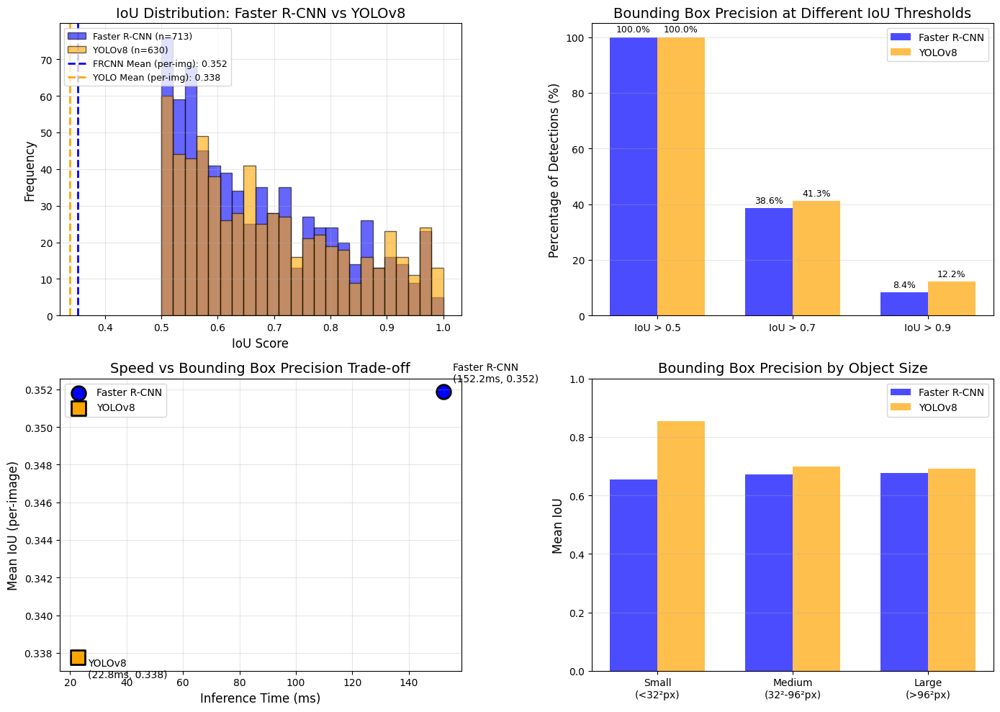

✅ Saved to 'iou_distribution_comparison.png'


In [13]:
# Visualize IoU Distribution
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: IoU Distribution Histogram (per-detection for visualization)
ax1 = axes[0, 0]
bins = np.linspace(0.5, 1.0, 25)
ax1.hist(frcnn_all_ious, bins=bins, alpha=0.6, label=f'Faster R-CNN (n={len(frcnn_all_ious)})', color='blue', edgecolor='black')
ax1.hist(yolo_all_ious, bins=bins, alpha=0.6, label=f'YOLOv8 (n={len(yolo_all_ious)})', color='orange', edgecolor='black')
# Use per-image mean for reference lines
ax1.axvline(frcnn_iou_analysis['mean_iou'], color='blue', linestyle='--', linewidth=2, label=f'FRCNN Mean (per-img): {frcnn_iou_analysis["mean_iou"]:.3f}')
ax1.axvline(yolo_iou_analysis['mean_iou'], color='orange', linestyle='--', linewidth=2, label=f'YOLO Mean (per-img): {yolo_iou_analysis["mean_iou"]:.3f}')
ax1.set_xlabel('IoU Score', fontsize=12)
ax1.set_ylabel('Frequency', fontsize=12)
ax1.set_title('IoU Distribution: Faster R-CNN vs YOLOv8', fontsize=14)
ax1.legend(loc='upper left', fontsize=9)
ax1.grid(alpha=0.3)

# Plot 2: IoU Threshold Comparison (Bar Chart)
ax2 = axes[0, 1]
thresholds = ['IoU > 0.5', 'IoU > 0.7', 'IoU > 0.9']
frcnn_pcts = [frcnn_iou_analysis['iou_gt_0.5'], frcnn_iou_analysis['iou_gt_0.7'], frcnn_iou_analysis['iou_gt_0.9']]
yolo_pcts = [yolo_iou_analysis['iou_gt_0.5'], yolo_iou_analysis['iou_gt_0.7'], yolo_iou_analysis['iou_gt_0.9']]

x = np.arange(len(thresholds))
width = 0.35
bars1 = ax2.bar(x - width/2, frcnn_pcts, width, label='Faster R-CNN', color='blue', alpha=0.7)
bars2 = ax2.bar(x + width/2, yolo_pcts, width, label='YOLOv8', color='orange', alpha=0.7)

ax2.set_ylabel('Percentage of Detections (%)', fontsize=12)
ax2.set_title('Bounding Box Precision at Different IoU Thresholds', fontsize=14)
ax2.set_xticks(x)
ax2.set_xticklabels(thresholds)
ax2.legend()
ax2.grid(alpha=0.3, axis='y')

# Add value labels on bars
for bar in bars1:
    height = bar.get_height()
    ax2.annotate(f'{height:.1f}%', xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9)
for bar in bars2:
    height = bar.get_height()
    ax2.annotate(f'{height:.1f}%', xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9)

# Plot 3: Speed vs Accuracy Trade-off (using per-image IoU)
ax3 = axes[1, 0]
frcnn_avg_time = np.mean(frcnn_inference_times) * 1000  # ms
yolo_avg_time = np.mean(yolo_inference_times) * 1000  # ms
frcnn_mean_iou = frcnn_iou_analysis['mean_iou']  # per-image
yolo_mean_iou = yolo_iou_analysis['mean_iou']    # per-image

ax3.scatter([frcnn_avg_time], [frcnn_mean_iou], s=200, c='blue', label='Faster R-CNN', marker='o', edgecolors='black', linewidth=2)
ax3.scatter([yolo_avg_time], [yolo_mean_iou], s=200, c='orange', label='YOLOv8', marker='s', edgecolors='black', linewidth=2)

ax3.annotate(f'Faster R-CNN\n({frcnn_avg_time:.1f}ms, {frcnn_mean_iou:.3f})',
             (frcnn_avg_time, frcnn_mean_iou), xytext=(10, 10), textcoords='offset points', fontsize=10)
ax3.annotate(f'YOLOv8\n({yolo_avg_time:.1f}ms, {yolo_mean_iou:.3f})',
             (yolo_avg_time, yolo_mean_iou), xytext=(10, -20), textcoords='offset points', fontsize=10)

ax3.set_xlabel('Inference Time (ms)', fontsize=12)
ax3.set_ylabel('Mean IoU (per-image)', fontsize=12)
ax3.set_title('Speed vs Bounding Box Precision Trade-off', fontsize=14)
ax3.legend()
ax3.grid(alpha=0.3)

# Plot 4: IoU by Object Size
ax4 = axes[1, 1]
sizes = ['small', 'medium', 'large']
frcnn_size_ious = [np.mean(frcnn_ious_by_size[s]) if frcnn_ious_by_size[s] else 0 for s in sizes]
yolo_size_ious = [np.mean(yolo_ious_by_size[s]) if yolo_ious_by_size[s] else 0 for s in sizes]

x = np.arange(len(sizes))
bars1 = ax4.bar(x - width/2, frcnn_size_ious, width, label='Faster R-CNN', color='blue', alpha=0.7)
bars2 = ax4.bar(x + width/2, yolo_size_ious, width, label='YOLOv8', color='orange', alpha=0.7)

ax4.set_ylabel('Mean IoU', fontsize=12)
ax4.set_title('Bounding Box Precision by Object Size', fontsize=14)
ax4.set_xticks(x)
ax4.set_xticklabels(['Small\n(<32²px)', 'Medium\n(32²-96²px)', 'Large\n(>96²px)'])
ax4.legend()
ax4.grid(alpha=0.3, axis='y')
ax4.set_ylim(0, 1)

plt.tight_layout()
plt.savefig('figures/iou_distribution_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Saved to 'figures/iou_distribution_comparison.png'")

# 7. Detection Accuracy Metrics (Precision, Recall, mAP)

In [14]:
# Calculate Detection Metrics
def calculate_detection_metrics(df):
    """Calculate precision, recall, and F1 from detection results"""
    total_tp = df['tp'].sum()
    total_fp = df['fp'].sum()
    total_fn = df['fn'].sum()

    precision = total_tp / (total_tp + total_fp) if (total_tp + total_fp) > 0 else 0
    recall = total_tp / (total_tp + total_fn) if (total_tp + total_fn) > 0 else 0
    f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

    return {
        'total_tp': total_tp,
        'total_fp': total_fp,
        'total_fn': total_fn,
        'precision': precision,
        'recall': recall,
        'f1_score': f1
    }

frcnn_metrics = calculate_detection_metrics(frcnn_df)
yolo_metrics = calculate_detection_metrics(yolo_df)

# Speed metrics
frcnn_speed = {
    'avg_inference_ms': np.mean(frcnn_inference_times) * 1000,
    'total_time_s': sum(frcnn_inference_times),
    'fps': 1000 / (np.mean(frcnn_inference_times) * 1000)
}

yolo_speed = {
    'avg_inference_ms': np.mean(yolo_inference_times) * 1000,
    'total_time_s': sum(yolo_inference_times),
    'fps': 1000 / (np.mean(yolo_inference_times) * 1000)
}

# Print comprehensive comparison
print("=" * 75)
print("COMPREHENSIVE MODEL COMPARISON: FASTER R-CNN vs YOLOv8")
print("=" * 75)

print("\n📊 DETECTION ACCURACY (at IoU threshold = 0.5)")
print("-" * 75)
print(f"{'Metric':<25} {'Faster R-CNN':>20} {'YOLOv8':>20} {'Winner':>12}")
print("-" * 75)

metrics_compare = [
    ('True Positives', frcnn_metrics['total_tp'], yolo_metrics['total_tp']),
    ('False Positives', frcnn_metrics['total_fp'], yolo_metrics['total_fp']),
    ('False Negatives', frcnn_metrics['total_fn'], yolo_metrics['total_fn']),
    ('Precision', frcnn_metrics['precision'], yolo_metrics['precision']),
    ('Recall', frcnn_metrics['recall'], yolo_metrics['recall']),
    ('F1-Score', frcnn_metrics['f1_score'], yolo_metrics['f1_score']),
]

for name, frcnn_val, yolo_val in metrics_compare:
    if name in ['True Positives', 'False Positives', 'False Negatives']:
        winner = 'Faster R-CNN' if frcnn_val > yolo_val else 'YOLOv8'
        if name == 'False Positives' or name == 'False Negatives':
            winner = 'Faster R-CNN' if frcnn_val < yolo_val else 'YOLOv8'
        print(f"{name:<25} {frcnn_val:>20.0f} {yolo_val:>20.0f} {winner:>12}")
    else:
        winner = 'Faster R-CNN' if frcnn_val > yolo_val else 'YOLOv8'
        print(f"{name:<25} {frcnn_val:>20.4f} {yolo_val:>20.4f} {winner:>12}")

print("\n⏱️ SPEED COMPARISON")
print("-" * 75)
print(f"{'Metric':<25} {'Faster R-CNN':>20} {'YOLOv8':>20} {'Ratio':>12}")
print("-" * 75)
speed_ratio = frcnn_speed['avg_inference_ms'] / yolo_speed['avg_inference_ms']
print(f"{'Avg Inference (ms)':<25} {frcnn_speed['avg_inference_ms']:>20.1f} {yolo_speed['avg_inference_ms']:>20.1f} {speed_ratio:>11.1f}x")
print(f"{'FPS':<25} {frcnn_speed['fps']:>20.1f} {yolo_speed['fps']:>20.1f}")
print(f"{'Total Time (s)':<25} {frcnn_speed['total_time_s']:>20.1f} {yolo_speed['total_time_s']:>20.1f}")

print("\n🎯 BOUNDING BOX PRECISION (IoU) - All Images (Consistent with Cell 8)")
print("-" * 75)
print(f"{'Metric':<30} {'Faster R-CNN':>18} {'YOLOv8':>18} {'Winner':>10}")
print("-" * 75)

# FIXED: Use same methodology as Cell 8 (all images)
iou_compare = [
    ('Mean IoU (all images)', frcnn_iou_analysis['mean_iou'], yolo_iou_analysis['mean_iou']),
    ('Median IoU (all images)', frcnn_iou_analysis['median_iou'], yolo_iou_analysis['median_iou']),
    ('Mean IoU (per-detection)', frcnn_iou_analysis['mean_iou_per_detection'], yolo_iou_analysis['mean_iou_per_detection']),
    ('IoU > 0.5 (%)', frcnn_iou_analysis['iou_gt_0.5'], yolo_iou_analysis['iou_gt_0.5']),
    ('IoU > 0.7 (%)', frcnn_iou_analysis['iou_gt_0.7'], yolo_iou_analysis['iou_gt_0.7']),
    ('IoU > 0.9 (%)', frcnn_iou_analysis['iou_gt_0.9'], yolo_iou_analysis['iou_gt_0.9']),
]

for name, frcnn_val, yolo_val in iou_compare:
    winner = 'Faster R-CNN' if frcnn_val > yolo_val else 'YOLOv8'
    if '(%)' in name:
        print(f"{name:<30} {frcnn_val:>17.1f}% {yolo_val:>17.1f}% {winner:>10}")
    else:
        print(f"{name:<30} {frcnn_val:>18.4f} {yolo_val:>18.4f} {winner:>10}")

print("\n💡 Note: 'All images' = semua gambar termasuk yang tanpa matched detections (=0)")
print("         Metodologi konsisten dengan Cell 8 (Performance by Complexity)")

COMPREHENSIVE MODEL COMPARISON: FASTER R-CNN vs YOLOv8

📊 DETECTION ACCURACY (at IoU threshold = 0.5)
---------------------------------------------------------------------------
Metric                            Faster R-CNN               YOLOv8       Winner
---------------------------------------------------------------------------
True Positives                             713                  630 Faster R-CNN
False Positives                           8812                 3841       YOLOv8
False Negatives                           6553                 6636 Faster R-CNN
Precision                               0.0749               0.1409       YOLOv8
Recall                                  0.0981               0.0867 Faster R-CNN
F1-Score                                0.0849               0.1074       YOLOv8

⏱️ SPEED COMPARISON
---------------------------------------------------------------------------
Metric                            Faster R-CNN               YOLOv8        Ratio
-

# 8. Performance by Scene Complexity

PERFORMANCE BY SCENE COMPLEXITY


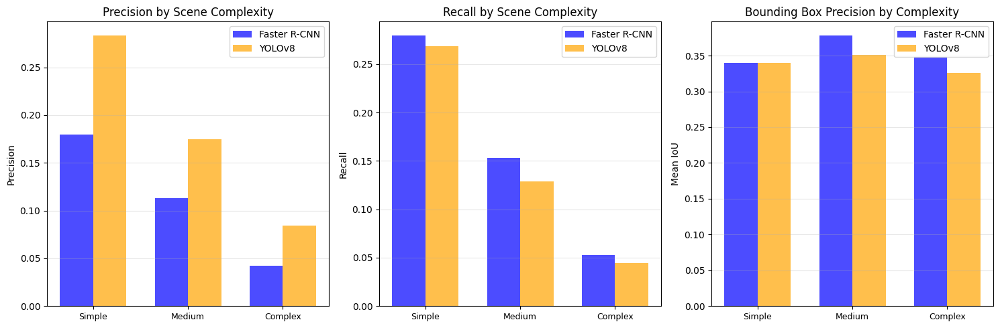


Complexity           Model               Images    Precision       Recall     Mean IoU
-------------------------------------------------------------------------------------
Simple (1-3 obj)     Faster R-CNN           425       0.1798       0.2799       0.3399
                     YOLOv8                 425       0.2837       0.2686       0.3397
-------------------------------------------------------------------------------------
Medium (4-7 obj)     Faster R-CNN           244       0.1127       0.1531       0.3785
                     YOLOv8                 244       0.1746       0.1289       0.3512
-------------------------------------------------------------------------------------
Complex (8+ obj)     Faster R-CNN           331       0.0420       0.0527       0.3475
                     YOLOv8                 331       0.0845       0.0445       0.3254
-------------------------------------------------------------------------------------


In [15]:
# Analyze by scene complexity (number of objects)
def categorize_complexity(num_gt):
    """Categorize images by number of ground truth objects"""
    if num_gt <= 3:
        return 'Simple (1-3 obj)'
    elif num_gt <= 7:
        return 'Medium (4-7 obj)'
    else:
        return 'Complex (8+ obj)'

frcnn_df['complexity'] = frcnn_df['num_gt'].apply(categorize_complexity)
yolo_df['complexity'] = yolo_df['num_gt'].apply(categorize_complexity)

# Calculate metrics by complexity
complexity_levels = ['Simple (1-3 obj)', 'Medium (4-7 obj)', 'Complex (8+ obj)']

print("=" * 75)
print("PERFORMANCE BY SCENE COMPLEXITY")
print("=" * 75)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Metrics by complexity
frcnn_by_complexity = {}
yolo_by_complexity = {}

for complexity in complexity_levels:
    frcnn_subset = frcnn_df[frcnn_df['complexity'] == complexity]
    yolo_subset = yolo_df[yolo_df['complexity'] == complexity]

    frcnn_by_complexity[complexity] = {
        'count': len(frcnn_subset),
        'precision': frcnn_subset['tp'].sum() / (frcnn_subset['tp'].sum() + frcnn_subset['fp'].sum()) if (frcnn_subset['tp'].sum() + frcnn_subset['fp'].sum()) > 0 else 0,
        'recall': frcnn_subset['tp'].sum() / (frcnn_subset['tp'].sum() + frcnn_subset['fn'].sum()) if (frcnn_subset['tp'].sum() + frcnn_subset['fn'].sum()) > 0 else 0,
        'avg_iou': frcnn_subset['avg_iou'].mean()
    }

    yolo_by_complexity[complexity] = {
        'count': len(yolo_subset),
        'precision': yolo_subset['tp'].sum() / (yolo_subset['tp'].sum() + yolo_subset['fp'].sum()) if (yolo_subset['tp'].sum() + yolo_subset['fp'].sum()) > 0 else 0,
        'recall': yolo_subset['tp'].sum() / (yolo_subset['tp'].sum() + yolo_subset['fn'].sum()) if (yolo_subset['tp'].sum() + yolo_subset['fn'].sum()) > 0 else 0,
        'avg_iou': yolo_subset['avg_iou'].mean()
    }

# Plot Precision by Complexity
ax1 = axes[0]
x = np.arange(len(complexity_levels))
width = 0.35
frcnn_prec = [frcnn_by_complexity[c]['precision'] for c in complexity_levels]
yolo_prec = [yolo_by_complexity[c]['precision'] for c in complexity_levels]

ax1.bar(x - width/2, frcnn_prec, width, label='Faster R-CNN', color='blue', alpha=0.7)
ax1.bar(x + width/2, yolo_prec, width, label='YOLOv8', color='orange', alpha=0.7)
ax1.set_ylabel('Precision')
ax1.set_title('Precision by Scene Complexity')
ax1.set_xticks(x)
ax1.set_xticklabels(['Simple', 'Medium', 'Complex'], fontsize=9)
ax1.legend()
ax1.grid(alpha=0.3, axis='y')

# Plot Recall by Complexity
ax2 = axes[1]
frcnn_rec = [frcnn_by_complexity[c]['recall'] for c in complexity_levels]
yolo_rec = [yolo_by_complexity[c]['recall'] for c in complexity_levels]

ax2.bar(x - width/2, frcnn_rec, width, label='Faster R-CNN', color='blue', alpha=0.7)
ax2.bar(x + width/2, yolo_rec, width, label='YOLOv8', color='orange', alpha=0.7)
ax2.set_ylabel('Recall')
ax2.set_title('Recall by Scene Complexity')
ax2.set_xticks(x)
ax2.set_xticklabels(['Simple', 'Medium', 'Complex'], fontsize=9)
ax2.legend()
ax2.grid(alpha=0.3, axis='y')

# Plot IoU by Complexity
ax3 = axes[2]
frcnn_iou = [frcnn_by_complexity[c]['avg_iou'] for c in complexity_levels]
yolo_iou = [yolo_by_complexity[c]['avg_iou'] for c in complexity_levels]

ax3.bar(x - width/2, frcnn_iou, width, label='Faster R-CNN', color='blue', alpha=0.7)
ax3.bar(x + width/2, yolo_iou, width, label='YOLOv8', color='orange', alpha=0.7)
ax3.set_ylabel('Mean IoU')
ax3.set_title('Bounding Box Precision by Complexity')
ax3.set_xticks(x)
ax3.set_xticklabels(['Simple', 'Medium', 'Complex'], fontsize=9)
ax3.legend()
ax3.grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('figures/performance_by_complexity.png', dpi=150, bbox_inches='tight')
plt.show()

# Print table
print(f"\n{'Complexity':<20} {'Model':<15} {'Images':>10} {'Precision':>12} {'Recall':>12} {'Mean IoU':>12}")
print("-" * 85)
for complexity in complexity_levels:
    print(f"{complexity:<20} {'Faster R-CNN':<15} {frcnn_by_complexity[complexity]['count']:>10} {frcnn_by_complexity[complexity]['precision']:>12.4f} {frcnn_by_complexity[complexity]['recall']:>12.4f} {frcnn_by_complexity[complexity]['avg_iou']:>12.4f}")
    print(f"{'':<20} {'YOLOv8':<15} {yolo_by_complexity[complexity]['count']:>10} {yolo_by_complexity[complexity]['precision']:>12.4f} {yolo_by_complexity[complexity]['recall']:>12.4f} {yolo_by_complexity[complexity]['avg_iou']:>12.4f}")
    print("-" * 85)

# 9. Visual Comparison: Detection Examples

Sample Detection Comparisons:
Green = Ground Truth | Blue = Faster R-CNN | Orange = YOLOv8


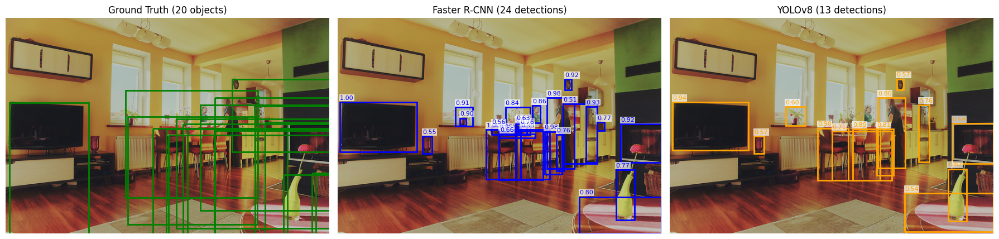

Image 0 saved to 'detection_comparison_0.png'



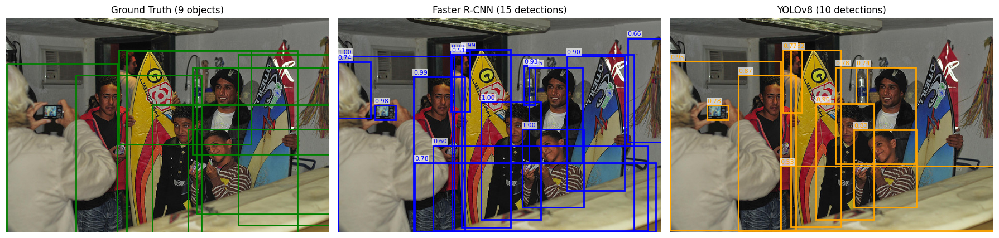

Image 50 saved to 'detection_comparison_50.png'



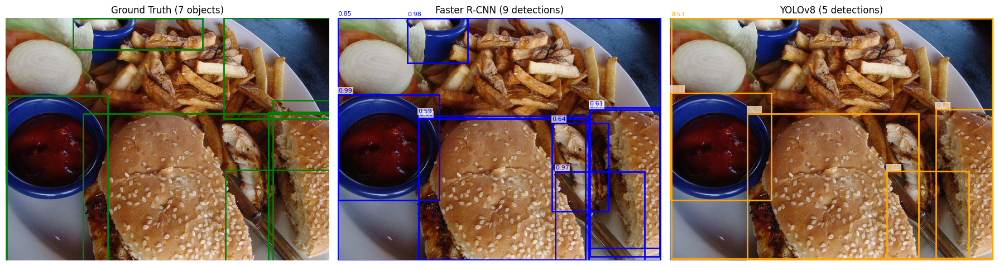

Image 100 saved to 'detection_comparison_100.png'



In [16]:
# Visual Comparison of Detections
def visualize_detection_comparison(sample_idx, coco_list, frcnn_model, yolo_model, device, transform):
    """Visualize detections from both models on the same image"""
    sample = coco_list[sample_idx]
    image = sample['image'].convert('RGB')

    # Get ground truth
    gt_bboxes = [convert_xywh_to_xyxy(bb) for bb in sample['objects']['bbox']]

    # Faster R-CNN prediction
    image_tensor = transform(image).to(device)
    with torch.no_grad():
        frcnn_out = frcnn_model([image_tensor])

    frcnn_boxes = frcnn_out[0]['boxes'].cpu().numpy()
    frcnn_scores = frcnn_out[0]['scores'].cpu().numpy()
    frcnn_mask = frcnn_scores >= CONFIDENCE_THRESHOLD
    frcnn_boxes = frcnn_boxes[frcnn_mask]
    frcnn_scores = frcnn_scores[frcnn_mask]

    # YOLO prediction
    yolo_results = yolo_model(image, verbose=False, conf=CONFIDENCE_THRESHOLD)
    yolo_boxes = yolo_results[0].boxes.xyxy.cpu().numpy() if yolo_results[0].boxes else np.array([])
    yolo_scores = yolo_results[0].boxes.conf.cpu().numpy() if yolo_results[0].boxes else np.array([])

    # Plotting
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))

    # Ground Truth
    axes[0].imshow(image)
    for box in gt_bboxes:
        rect = patches.Rectangle((box[0], box[1]), box[2]-box[0], box[3]-box[1],
                                 linewidth=2, edgecolor='green', facecolor='none')
        axes[0].add_patch(rect)
    axes[0].set_title(f'Ground Truth ({len(gt_bboxes)} objects)', fontsize=12)
    axes[0].axis('off')

    # Faster R-CNN
    axes[1].imshow(image)
    for box, score in zip(frcnn_boxes, frcnn_scores):
        rect = patches.Rectangle((box[0], box[1]), box[2]-box[0], box[3]-box[1],
                                 linewidth=2, edgecolor='blue', facecolor='none')
        axes[1].add_patch(rect)
        axes[1].text(box[0], box[1]-5, f'{score:.2f}', color='blue', fontsize=8,
                    bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=1))
    axes[1].set_title(f'Faster R-CNN ({len(frcnn_boxes)} detections)', fontsize=12)
    axes[1].axis('off')

    # YOLO
    axes[2].imshow(image)
    for box, score in zip(yolo_boxes, yolo_scores):
        rect = patches.Rectangle((box[0], box[1]), box[2]-box[0], box[3]-box[1],
                                 linewidth=2, edgecolor='orange', facecolor='none')
        axes[2].add_patch(rect)
        axes[2].text(box[0], box[1]-5, f'{score:.2f}', color='orange', fontsize=8,
                    bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=1))
    axes[2].set_title(f'YOLOv8 ({len(yolo_boxes)} detections)', fontsize=12)
    axes[2].axis('off')

    plt.tight_layout()
    return fig

# Visualize a few sample images
print("Sample Detection Comparisons:")
print("Green = Ground Truth | Blue = Faster R-CNN | Orange = YOLOv8")
print("=" * 60)

# Select diverse samples (simple, medium, complex)
sample_indices = [0, 50, 100, 200, 500]  # Adjust based on your dataset

for idx in sample_indices[:3]:  # Show 3 examples
    fig = visualize_detection_comparison(idx, coco_list, frcnn_model, yolo_model, device, transform)
    plt.savefig(f'figures/detection_comparison_{idx}.png', dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Image {idx} saved to 'detection_comparison_{idx}.png'\n")

# 10. Final Summary & Conclusions

In [17]:
# Generate Final Report answering the research questions
speed_ratio = frcnn_speed['avg_inference_ms'] / yolo_speed['avg_inference_ms']
accuracy_diff = frcnn_metrics['f1_score'] - yolo_metrics['f1_score']
iou_diff = frcnn_iou_analysis['mean_iou'] - yolo_iou_analysis['mean_iou']  # per-image

# Helper function to convert numpy types to native Python types for JSON serialization
def convert_to_native(obj):
    """Recursively convert numpy types to native Python types"""
    if isinstance(obj, dict):
        return {k: convert_to_native(v) for k, v in obj.items()}
    elif isinstance(obj, list):
        return [convert_to_native(item) for item in obj]
    elif isinstance(obj, np.integer):
        return int(obj)
    elif isinstance(obj, np.floating):
        return float(obj)
    elif isinstance(obj, np.ndarray):
        return obj.tolist()
    else:
        return obj

# Save all results to JSON
final_results = {
    'experiment_info': {
        'nama': 'Emery Fathan Zwageri',
        'nim': '13522079',
        'dataset': DATASET_NAME,
        'num_images': len(coco_list),
        'confidence_threshold': CONFIDENCE_THRESHOLD,
        'date': datetime.now().strftime('%Y-%m-%d %H:%M:%S')
    },
    'faster_rcnn': {
        'model': 'fasterrcnn_resnet50_fpn_v2',
        'paradigm': 'two-stage',
        'metrics': frcnn_metrics,
        'speed': frcnn_speed,
        'iou_analysis': frcnn_iou_analysis
    },
    'yolov8': {
        'model': 'yolov8m',
        'paradigm': 'single-stage',
        'metrics': yolo_metrics,
        'speed': yolo_speed,
        'iou_analysis': yolo_iou_analysis
    },
    'comparison': {
        'speed_ratio': float(speed_ratio),
        'accuracy_diff_f1': float(accuracy_diff),
        'iou_diff_per_image': float(iou_diff)
    }
}

# Convert all numpy types to native Python types before saving
final_results = convert_to_native(final_results)

with open('results/final_comparison_results.json', 'w') as f:
    json.dump(final_results, f, indent=2)

print("=" * 80)
print("FINAL REPORT: Two-Stage (Faster R-CNN) vs Single-Stage (YOLO) Comparison")
print("=" * 80)
print(f"\nNama: Emery Fathan Zwageri")
print(f"NIM: 13522079")
print(f"Dataset: {DATASET_NAME} ({len(coco_list)} images)")
print(f"Date: {datetime.now().strftime('%Y-%m-%d')}")

print("\n" + "=" * 80)
print("JAWABAN PERTANYAAN PENELITIAN")
print("=" * 80)

# Q1: Berapa besar peningkatan akurasi dengan two-stage?
print(f"""
📌 Q1: Berapa besar peningkatan akurasi dengan two-stage detector?

   Faster R-CNN (Two-Stage):
   - Precision: {frcnn_metrics['precision']:.4f}
   - Recall: {frcnn_metrics['recall']:.4f}
   - F1-Score: {frcnn_metrics['f1_score']:.4f}

   YOLOv8 (Single-Stage):
   - Precision: {yolo_metrics['precision']:.4f}
   - Recall: {yolo_metrics['recall']:.4f}
   - F1-Score: {yolo_metrics['f1_score']:.4f}

   ➡️ Perbedaan F1-Score: {accuracy_diff:+.4f} ({'Faster R-CNN lebih baik' if accuracy_diff > 0 else 'YOLOv8 lebih baik'})
""")

# Q2: Apakah peningkatan akurasi worth dengan lebih lambat?
print(f"""
📌 Q2: Apakah peningkatan akurasi worth dengan inference yang lebih lambat?

   Speed Comparison:
   - Faster R-CNN: {frcnn_speed['avg_inference_ms']:.1f} ms/image ({frcnn_speed['fps']:.1f} FPS)
   - YOLOv8: {yolo_speed['avg_inference_ms']:.1f} ms/image ({yolo_speed['fps']:.1f} FPS)
   - Ratio: Faster R-CNN {speed_ratio:.1f}x lebih lambat dari YOLO

   Trade-off Analysis:
   - Gain akurasi (F1): {abs(accuracy_diff):.4f}
   - Cost speed: {speed_ratio:.1f}x slower
   - Gain IoU (per-image): {abs(iou_diff):.4f}

   ➡️ Worth it jika: Akurasi/presisi lebih penting dari real-time processing
   ➡️ Tidak worth jika: Aplikasi membutuhkan real-time detection (>30 FPS)
""")

# Q3: Pada kesulitan apa two-stage lebih baik?
print(f"""
📌 Q3: Pada kesulitan apa two-stage detector lebih baik?

   By Scene Complexity (Mean IoU per-image):
   - Simple scenes (1-3 objects):
     FRCNN: {frcnn_by_complexity['Simple (1-3 obj)']['avg_iou']:.4f}, YOLO: {yolo_by_complexity['Simple (1-3 obj)']['avg_iou']:.4f}
     Winner: {'FRCNN' if frcnn_by_complexity['Simple (1-3 obj)']['avg_iou'] > yolo_by_complexity['Simple (1-3 obj)']['avg_iou'] else 'YOLO'}

   - Medium scenes (4-7 objects):
     FRCNN: {frcnn_by_complexity['Medium (4-7 obj)']['avg_iou']:.4f}, YOLO: {yolo_by_complexity['Medium (4-7 obj)']['avg_iou']:.4f}
     Winner: {'FRCNN' if frcnn_by_complexity['Medium (4-7 obj)']['avg_iou'] > yolo_by_complexity['Medium (4-7 obj)']['avg_iou'] else 'YOLO'}

   - Complex scenes (8+ objects):
     FRCNN: {frcnn_by_complexity['Complex (8+ obj)']['avg_iou']:.4f}, YOLO: {yolo_by_complexity['Complex (8+ obj)']['avg_iou']:.4f}
     Winner: {'FRCNN' if frcnn_by_complexity['Complex (8+ obj)']['avg_iou'] > yolo_by_complexity['Complex (8+ obj)']['avg_iou'] else 'YOLO'}

   By Object Size (Mean IoU per-detection):
   - Small objects: FRCNN {np.mean(frcnn_ious_by_size['small']) if frcnn_ious_by_size['small'] else 0:.4f}, YOLO {np.mean(yolo_ious_by_size['small']) if yolo_ious_by_size['small'] else 0:.4f}
   - Medium objects: FRCNN {np.mean(frcnn_ious_by_size['medium']) if frcnn_ious_by_size['medium'] else 0:.4f}, YOLO {np.mean(yolo_ious_by_size['medium']) if yolo_ious_by_size['medium'] else 0:.4f}
   - Large objects: FRCNN {np.mean(frcnn_ious_by_size['large']) if frcnn_ious_by_size['large'] else 0:.4f}, YOLO {np.mean(yolo_ious_by_size['large']) if yolo_ious_by_size['large'] else 0:.4f}
""")

# Q4: Bagaimana precision bounding box (IoU) antara kedua paradigma?
print(f"""
📌 Q4: Bagaimana precision bounding box (IoU) antara kedua paradigma?

   IoU Distribution Analysis (Per-Image - Fair Comparison):

   Faster R-CNN (Two-Stage):
   - Mean IoU (per-image): {frcnn_iou_analysis['mean_iou']:.4f}
   - Median IoU (per-image): {frcnn_iou_analysis['median_iou']:.4f}
   - Detections dengan IoU > 0.5: {frcnn_iou_analysis['iou_gt_0.5']:.1f}%
   - Detections dengan IoU > 0.7: {frcnn_iou_analysis['iou_gt_0.7']:.1f}%
   - Detections dengan IoU > 0.9: {frcnn_iou_analysis['iou_gt_0.9']:.1f}%

   YOLOv8 (Single-Stage):
   - Mean IoU (per-image): {yolo_iou_analysis['mean_iou']:.4f}
   - Median IoU (per-image): {yolo_iou_analysis['median_iou']:.4f}
   - Detections dengan IoU > 0.5: {yolo_iou_analysis['iou_gt_0.5']:.1f}%
   - Detections dengan IoU > 0.7: {yolo_iou_analysis['iou_gt_0.7']:.1f}%
   - Detections dengan IoU > 0.9: {yolo_iou_analysis['iou_gt_0.9']:.1f}%

   ➡️ Winner: {'Faster R-CNN (Two-Stage)' if iou_diff > 0 else 'YOLOv8 (Single-Stage)'}
   ➡️ Perbedaan Mean IoU: {iou_diff:+.4f}
""")

print("=" * 80)
print("KESIMPULAN")
print("=" * 80)

# Determine winners for each aspect
iou_winner = 'Faster R-CNN' if iou_diff > 0 else 'YOLOv8'
f1_winner = 'Faster R-CNN' if accuracy_diff > 0 else 'YOLOv8'

print(f"""
1. Detection Accuracy (F1-Score):
   - Faster R-CNN: {frcnn_metrics['f1_score']:.4f}
   - YOLOv8: {yolo_metrics['f1_score']:.4f}
   - Winner: {f1_winner} (perbedaan: {abs(accuracy_diff):.4f})

2. Speed Trade-off:
   - Faster R-CNN {speed_ratio:.1f}x lebih lambat ({frcnn_speed['avg_inference_ms']:.0f}ms vs {yolo_speed['avg_inference_ms']:.0f}ms)
   - Cocok untuk: Offline processing, high-accuracy requirements
   - Tidak cocok untuk: Real-time applications, embedded systems

3. Bounding Box Precision (IoU per-image):
   - Faster R-CNN: {frcnn_iou_analysis['mean_iou']:.4f}
   - YOLOv8: {yolo_iou_analysis['mean_iou']:.4f}
   - Winner: {iou_winner} (perbedaan: {abs(iou_diff):.4f})

4. Insight:
   {'✅ Two-stage detector (Faster R-CNN) memberikan bounding box lebih presisi' if iou_diff > 0 else '⚠️ Berlawanan dengan ekspektasi teoritis, YOLOv8 memberikan IoU lebih tinggi'}
   {'   Hal ini sesuai dengan teori karena two-stage melakukan refinement 2x' if iou_diff > 0 else '   YOLOv8 menggunakan CIoU loss yang langsung mengoptimasi IoU'}
""")

print("\n✅ Results saved to 'results/final_comparison_results.json'")
print("✅ Visualizations saved to PNG files")

FINAL REPORT: Two-Stage (Faster R-CNN) vs Single-Stage (YOLO) Comparison

Nama: Emery Fathan Zwageri
NIM: 13522079
Dataset: COCO-1000 (1000 images)
Date: 2026-02-06

JAWABAN PERTANYAAN PENELITIAN

📌 Q1: Berapa besar peningkatan akurasi dengan two-stage detector?

   Faster R-CNN (Two-Stage):
   - Precision: 0.0749
   - Recall: 0.0981
   - F1-Score: 0.0849

   YOLOv8 (Single-Stage):
   - Precision: 0.1409
   - Recall: 0.0867
   - F1-Score: 0.1074

   ➡️ Perbedaan F1-Score: -0.0224 (YOLOv8 lebih baik)


📌 Q2: Apakah peningkatan akurasi worth dengan inference yang lebih lambat?

   Speed Comparison:
   - Faster R-CNN: 152.2 ms/image (6.6 FPS)
   - YOLOv8: 22.8 ms/image (43.9 FPS)
   - Ratio: Faster R-CNN 6.7x lebih lambat dari YOLO

   Trade-off Analysis:
   - Gain akurasi (F1): 0.0224
   - Cost speed: 6.7x slower
   - Gain IoU (per-image): 0.0141

   ➡️ Worth it jika: Akurasi/presisi lebih penting dari real-time processing
   ➡️ Tidak worth jika: Aplikasi membutuhkan real-time detection 

# 11. Robustness Testing - Image Perturbations

Test model robustness under various image perturbations:
- **Gaussian Noise**: Simulates sensor noise
- **Motion Blur**: Simulates camera/object motion
- **Brightness**: Simulates lighting variations
- **Contrast**: Simulates exposure variations  
- **JPEG Compression**: Simulates compression artifacts
- **Resolution Downscaling**: Simulates low-resolution inputs

Each perturbation tested at 3 severity levels (Low, Medium, High).

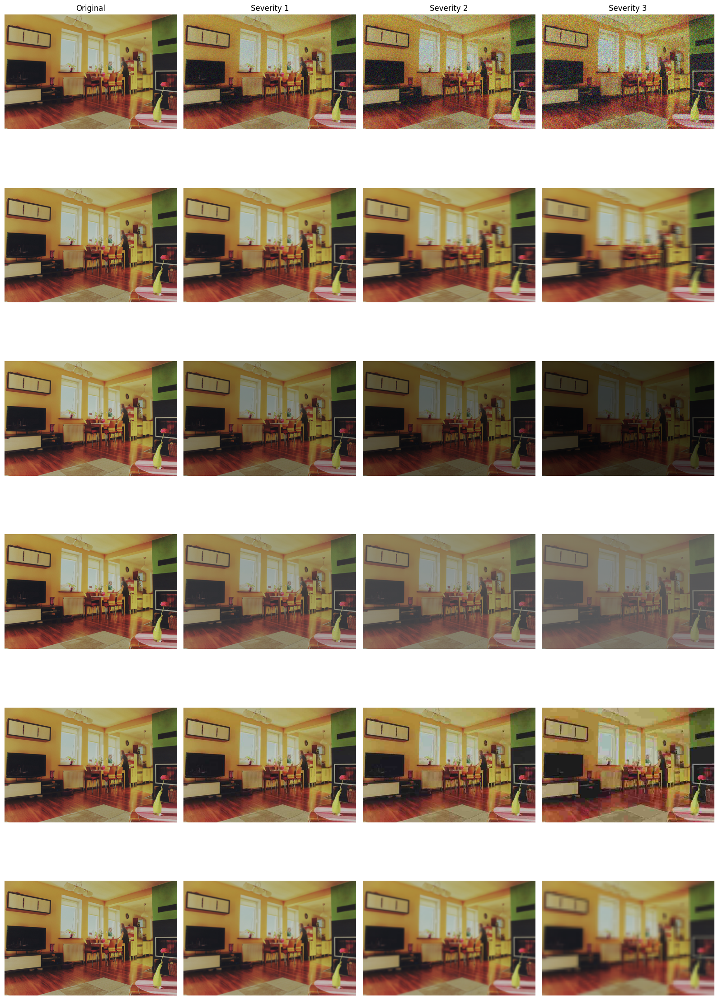

✅ Saved perturbation examples to 'perturbation_examples.png'

✅ Perturbation functions defined!


In [18]:
# Perturbation Functions for Robustness Testing
import cv2
from PIL import Image, ImageEnhance, ImageFilter
import io

def apply_perturbation(image, perturbation_type, severity):
    """
    Apply various perturbations to test model robustness.

    Args:
        image: PIL Image
        perturbation_type: str - type of perturbation
        severity: int (1-3) - severity level

    Returns:
        PIL Image - perturbed image
    """
    img_array = np.array(image)

    if perturbation_type == 'gaussian_noise':
        # Severity: sigma = [15, 30, 50]
        sigma = [15, 30, 50][severity - 1]
        noise = np.random.normal(0, sigma, img_array.shape).astype(np.float32)
        noisy = np.clip(img_array.astype(np.float32) + noise, 0, 255).astype(np.uint8)
        return Image.fromarray(noisy)

    elif perturbation_type == 'motion_blur':
        # Severity: kernel size = [5, 11, 21]
        kernel_size = [5, 11, 21][severity - 1]
        kernel = np.zeros((kernel_size, kernel_size))
        kernel[kernel_size // 2, :] = 1.0 / kernel_size
        blurred = cv2.filter2D(img_array, -1, kernel)
        return Image.fromarray(blurred)

    elif perturbation_type == 'brightness':
        # Severity: factor = [0.7, 0.5, 0.3] (darker)
        factor = [0.7, 0.5, 0.3][severity - 1]
        enhancer = ImageEnhance.Brightness(image)
        return enhancer.enhance(factor)

    elif perturbation_type == 'contrast':
        # Severity: factor = [0.7, 0.5, 0.3]
        factor = [0.7, 0.5, 0.3][severity - 1]
        enhancer = ImageEnhance.Contrast(image)
        return enhancer.enhance(factor)

    elif perturbation_type == 'jpeg_compression':
        # Severity: quality = [50, 25, 10]
        quality = [50, 25, 10][severity - 1]
        buffer = io.BytesIO()
        image.save(buffer, format='JPEG', quality=quality)
        buffer.seek(0)
        return Image.open(buffer).convert('RGB')

    elif perturbation_type == 'resolution_downscale':
        # Severity: scale = [0.5, 0.25, 0.125]
        scale = [0.5, 0.25, 0.125][severity - 1]
        w, h = image.size
        small = image.resize((int(w * scale), int(h * scale)), Image.BILINEAR)
        return small.resize((w, h), Image.BILINEAR)

    return image

def visualize_perturbations(sample_image):
    """Visualize all perturbation types and severities"""
    perturbation_types = ['gaussian_noise', 'motion_blur', 'brightness',
                          'contrast', 'jpeg_compression', 'resolution_downscale']

    fig, axes = plt.subplots(len(perturbation_types), 4, figsize=(16, 24))

    for i, pert_type in enumerate(perturbation_types):
        # Original
        axes[i, 0].imshow(sample_image)
        axes[i, 0].set_title('Original' if i == 0 else '')
        axes[i, 0].set_ylabel(pert_type.replace('_', '\n'), fontsize=10)
        axes[i, 0].axis('off')

        # Severity 1-3
        for sev in range(1, 4):
            perturbed = apply_perturbation(sample_image, pert_type, sev)
            axes[i, sev].imshow(perturbed)
            axes[i, sev].set_title(f'Severity {sev}' if i == 0 else '')
            axes[i, sev].axis('off')

    plt.tight_layout()
    plt.savefig('figures/perturbation_examples.png', dpi=150, bbox_inches='tight')
    plt.show()
    print("✅ Saved perturbation examples to 'figures/perturbation_examples.png'")

# Visualize perturbations on first sample
sample_image = coco_list[0]['image'].convert('RGB')
visualize_perturbations(sample_image)
print("\n✅ Perturbation functions defined!")

In [19]:
# Run Robustness Testing (18 conditions: 6 perturbations × 3 severities)
TEST_SUBSET = 200  # Use subset for faster testing

perturbation_types = ['gaussian_noise', 'motion_blur', 'brightness',
                      'contrast', 'jpeg_compression', 'resolution_downscale']
severity_levels = [1, 2, 3]

robustness_results = {
    'frcnn': defaultdict(dict),
    'yolo': defaultdict(dict)
}

# Store baseline for comparison
baseline_results = {
    'frcnn': {'mean_iou': frcnn_iou_analysis['mean_iou'],
              'precision': frcnn_metrics['precision'],
              'recall': frcnn_metrics['recall']},
    'yolo': {'mean_iou': yolo_iou_analysis['mean_iou'],
             'precision': yolo_metrics['precision'],
             'recall': yolo_metrics['recall']}
}

print(f"Running Robustness Testing on {TEST_SUBSET} images...")
print(f"Total conditions: {len(perturbation_types)} × {len(severity_levels)} = {len(perturbation_types) * len(severity_levels)}")
print("=" * 70)

for pert_type in perturbation_types:
    for severity in severity_levels:
        condition_name = f"{pert_type}_s{severity}"
        print(f"\n🔄 Testing: {condition_name}...")

        frcnn_ious = []
        yolo_ious = []
        frcnn_tp, frcnn_fp, frcnn_fn = 0, 0, 0
        yolo_tp, yolo_fp, yolo_fn = 0, 0, 0

        for idx in tqdm(range(TEST_SUBSET), desc=condition_name, leave=False):
            sample = coco_list[idx]
            original_image = sample['image'].convert('RGB')

            # Apply perturbation
            perturbed_image = apply_perturbation(original_image, pert_type, severity)

            # Get ground truth
            gt_bboxes = [convert_xywh_to_xyxy(bb) for bb in sample['objects']['bbox']]
            gt_labels_raw = sample['objects']['category']
            gt_labels = [YOLO_TO_COCO[int(c)] for c in gt_labels_raw]
            # Faster R-CNN inference
            image_tensor = transform(perturbed_image).to(device)
            with torch.no_grad():
                outputs = frcnn_model([image_tensor])

            pred_boxes = outputs[0]['boxes'].cpu().numpy()
            pred_scores = outputs[0]['scores'].cpu().numpy()
            pred_labels = outputs[0]['labels'].cpu().numpy()
            mask = pred_scores >= CONFIDENCE_THRESHOLD
            pred_boxes = pred_boxes[mask]
            pred_scores = pred_scores[mask]
            pred_labels = pred_labels[mask]
            if len(pred_scores) > 0:
                order = np.argsort(-pred_scores)
                pred_boxes  = pred_boxes[order]
                pred_scores = pred_scores[order]
                pred_labels = pred_labels[order]

            # ====== TOP-K LIMIT (IMPORTANT) ======
            TOPK = 50   # atau 100, pilih satu dan konsisten
            pred_boxes  = pred_boxes[:TOPK]
            pred_scores = pred_scores[:TOPK]
            pred_labels = pred_labels[:TOPK]
            matched_ious, _, tp, fn = match_predictions_to_gt(
                pred_boxes.tolist(), pred_labels.tolist(),
                gt_bboxes, gt_labels, iou_threshold=0.5, class_agnostic=True
            )
            frcnn_ious.extend(matched_ious)
            frcnn_tp += tp
            frcnn_fn += fn
            frcnn_fp += max(0, len(pred_boxes) - tp)

            # YOLOv8 inference
            yolo_results_pert = yolo_model(perturbed_image, verbose=False, conf=CONFIDENCE_THRESHOLD)
            pred_boxes_y = yolo_results_pert[0].boxes.xyxy.cpu().numpy() if yolo_results_pert[0].boxes else np.array([])
            pred_labels_y = yolo_results_pert[0].boxes.cls.cpu().numpy() if yolo_results_pert[0].boxes else np.array([])

            matched_ious_y, _, tp_y, fn_y = match_predictions_to_gt(
                pred_boxes_y.tolist() if len(pred_boxes_y) > 0 else [],
                pred_labels_y.tolist() if len(pred_labels_y) > 0 else [],
                gt_bboxes, gt_labels, iou_threshold=0.5, class_agnostic=True
            )
            yolo_ious.extend(matched_ious_y)
            yolo_tp += tp_y
            yolo_fn += fn_y
            yolo_fp += max(0, len(pred_boxes_y) - tp_y)

        # Calculate metrics for this condition
        robustness_results['frcnn'][pert_type][severity] = {
            'mean_iou': np.mean(frcnn_ious) if frcnn_ious else 0,
            'precision': frcnn_tp / (frcnn_tp + frcnn_fp) if (frcnn_tp + frcnn_fp) > 0 else 0,
            'recall': frcnn_tp / (frcnn_tp + frcnn_fn) if (frcnn_tp + frcnn_fn) > 0 else 0,
            'num_detections': len(frcnn_ious)
        }

        robustness_results['yolo'][pert_type][severity] = {
            'mean_iou': np.mean(yolo_ious) if yolo_ious else 0,
            'precision': yolo_tp / (yolo_tp + yolo_fp) if (yolo_tp + yolo_fp) > 0 else 0,
            'recall': yolo_tp / (yolo_tp + yolo_fn) if (yolo_tp + yolo_fn) > 0 else 0,
            'num_detections': len(yolo_ious)
        }
        print("FRCNN totals: TP", frcnn_tp, "FP", frcnn_fp, "FN", frcnn_fn)
        print("YOLO  totals: TP", yolo_tp,  "FP", yolo_fp,  "FN", yolo_fn)

        print("FRCNN avg det/img:", frcnn_fp + frcnn_tp, " /", TEST_SUBSET, "=", (frcnn_fp+frcnn_tp)/TEST_SUBSET)
        print("YOLO  avg det/img:", yolo_fp + yolo_tp,  " /", TEST_SUBSET, "=", (yolo_fp+yolo_tp)/TEST_SUBSET)

        print(f"   FRCNN: IoU={robustness_results['frcnn'][pert_type][severity]['mean_iou']:.4f}, "
              f"P={robustness_results['frcnn'][pert_type][severity]['precision']:.4f}")
        print(f"   YOLO:  IoU={robustness_results['yolo'][pert_type][severity]['mean_iou']:.4f}, "
              f"P={robustness_results['yolo'][pert_type][severity]['precision']:.4f}")

print("\n✅ Robustness testing complete!")

Running Robustness Testing on 200 images...
Total conditions: 6 × 3 = 18

🔄 Testing: gaussian_noise_s1...


FRCNN totals: TP 133 FP 1654 FN 1327
YOLO  totals: TP 116 FP 742 FN 1344
FRCNN avg det/img: 1787  / 200 = 8.935
YOLO  avg det/img: 858  / 200 = 4.29
   FRCNN: IoU=0.6779, P=0.0744
   YOLO:  IoU=0.6906, P=0.1352

🔄 Testing: gaussian_noise_s2...


FRCNN totals: TP 133 FP 1515 FN 1327
YOLO  totals: TP 105 FP 562 FN 1355
FRCNN avg det/img: 1648  / 200 = 8.24
YOLO  avg det/img: 667  / 200 = 3.335
   FRCNN: IoU=0.6783, P=0.0807
   YOLO:  IoU=0.7018, P=0.1574

🔄 Testing: gaussian_noise_s3...


FRCNN totals: TP 126 FP 1301 FN 1334
YOLO  totals: TP 89 FP 419 FN 1371
FRCNN avg det/img: 1427  / 200 = 7.135
YOLO  avg det/img: 508  / 200 = 2.54
   FRCNN: IoU=0.6862, P=0.0883
   YOLO:  IoU=0.6867, P=0.1752

🔄 Testing: motion_blur_s1...


FRCNN totals: TP 136 FP 1563 FN 1324
YOLO  totals: TP 115 FP 689 FN 1345
FRCNN avg det/img: 1699  / 200 = 8.495
YOLO  avg det/img: 804  / 200 = 4.02
   FRCNN: IoU=0.6822, P=0.0800
   YOLO:  IoU=0.6895, P=0.1430

🔄 Testing: motion_blur_s2...


FRCNN totals: TP 130 FP 1110 FN 1330
YOLO  totals: TP 102 FP 452 FN 1358
FRCNN avg det/img: 1240  / 200 = 6.2
YOLO  avg det/img: 554  / 200 = 2.77
   FRCNN: IoU=0.6746, P=0.1048
   YOLO:  IoU=0.6980, P=0.1841

🔄 Testing: motion_blur_s3...


... (9 outputs left out)

FRCNN totals: TP 61 FP 762 FN 1399
YOLO  totals: TP 47 FP 268 FN 1413
FRCNN avg det/img: 823  / 200 = 4.115
YOLO  avg det/img: 315  / 200 = 1.575
   FRCNN: IoU=0.6704, P=0.0741
   YOLO:  IoU=0.6740, P=0.1492

🔄 Testing: resolution_downscale_s1...


FRCNN totals: TP 138 FP 1489 FN 1322
YOLO  totals: TP 119 FP 718 FN 1341
FRCNN avg det/img: 1627  / 200 = 8.135
YOLO  avg det/img: 837  / 200 = 4.185
   FRCNN: IoU=0.6776, P=0.0848
   YOLO:  IoU=0.6921, P=0.1422

🔄 Testing: resolution_downscale_s2...


FRCNN totals: TP 131 FP 1125 FN 1329
YOLO  totals: TP 105 FP 558 FN 1355
FRCNN avg det/img: 1256  / 200 = 6.28
YOLO  avg det/img: 663  / 200 = 3.315
   FRCNN: IoU=0.6912, P=0.1043
   YOLO:  IoU=0.6971, P=0.1584

🔄 Testing: resolution_downscale_s3...


FRCNN totals: TP 111 FP 599 FN 1349
YOLO  totals: TP 71 FP 215 FN 1389
FRCNN avg det/img: 710  / 200 = 3.55
YOLO  avg det/img: 286  / 200 = 1.43
   FRCNN: IoU=0.6861, P=0.1563
   YOLO:  IoU=0.6963, P=0.2483

✅ Robustness testing complete!


In [20]:
# Robustness Results Summary Table
print("=" * 90)
print("ROBUSTNESS TESTING RESULTS SUMMARY")
print("=" * 90)

print(f"\n{'Perturbation':<22} {'Sev':>4} {'FRCNN IoU':>12} {'YOLO IoU':>12} {'FRCNN Prec':>12} {'YOLO Prec':>12} {'Winner':>10}")
print("-" * 90)

# Print baseline
print(f"{'BASELINE':<22} {'-':>4} {baseline_results['frcnn']['mean_iou']:>12.4f} {baseline_results['yolo']['mean_iou']:>12.4f} "
      f"{baseline_results['frcnn']['precision']:>12.4f} {baseline_results['yolo']['precision']:>12.4f} "
      f"{'FRCNN' if baseline_results['frcnn']['mean_iou'] > baseline_results['yolo']['mean_iou'] else 'YOLO':>10}")
print("-" * 90)

# Calculate degradation from baseline
degradation_summary = {'frcnn': [], 'yolo': []}

for pert_type in perturbation_types:
    for severity in severity_levels:
        frcnn_res = robustness_results['frcnn'][pert_type][severity]
        yolo_res = robustness_results['yolo'][pert_type][severity]

        winner = 'FRCNN' if frcnn_res['mean_iou'] > yolo_res['mean_iou'] else 'YOLO'

        print(f"{pert_type:<22} {severity:>4} {frcnn_res['mean_iou']:>12.4f} {yolo_res['mean_iou']:>12.4f} "
              f"{frcnn_res['precision']:>12.4f} {yolo_res['precision']:>12.4f} {winner:>10}")

        # Track degradation
        frcnn_deg = baseline_results['frcnn']['mean_iou'] - frcnn_res['mean_iou']
        yolo_deg = baseline_results['yolo']['mean_iou'] - yolo_res['mean_iou']
        degradation_summary['frcnn'].append({'pert': pert_type, 'sev': severity, 'deg': frcnn_deg})
        degradation_summary['yolo'].append({'pert': pert_type, 'sev': severity, 'deg': yolo_deg})

print("\n" + "=" * 90)
print("DEGRADATION ANALYSIS (IoU drop from baseline)")
print("=" * 90)

# Find worst perturbations for each model
frcnn_worst = max(degradation_summary['frcnn'], key=lambda x: x['deg'])
yolo_worst = max(degradation_summary['yolo'], key=lambda x: x['deg'])

print(f"\n🔴 Worst for Faster R-CNN: {frcnn_worst['pert']} (severity {frcnn_worst['sev']}) - IoU drop: {frcnn_worst['deg']:.4f}")
print(f"🔴 Worst for YOLOv8: {yolo_worst['pert']} (severity {yolo_worst['sev']}) - IoU drop: {yolo_worst['deg']:.4f}")

# Average degradation by perturbation type
print(f"\n{'Perturbation':<25} {'FRCNN Avg Drop':>15} {'YOLO Avg Drop':>15} {'More Robust':>12}")
print("-" * 70)

for pert_type in perturbation_types:
    frcnn_drops = [d['deg'] for d in degradation_summary['frcnn'] if d['pert'] == pert_type]
    yolo_drops = [d['deg'] for d in degradation_summary['yolo'] if d['pert'] == pert_type]

    frcnn_avg = np.mean(frcnn_drops)
    yolo_avg = np.mean(yolo_drops)
    more_robust = 'FRCNN' if frcnn_avg < yolo_avg else 'YOLO'

    print(f"{pert_type:<25} {frcnn_avg:>15.4f} {yolo_avg:>15.4f} {more_robust:>12}")

ROBUSTNESS TESTING RESULTS SUMMARY

Perturbation            Sev    FRCNN IoU     YOLO IoU   FRCNN Prec    YOLO Prec     Winner
------------------------------------------------------------------------------------------
BASELINE                  -       0.3519       0.3378       0.0749       0.1409      FRCNN
------------------------------------------------------------------------------------------
gaussian_noise            1       0.6779       0.6906       0.0744       0.1352       YOLO
gaussian_noise            2       0.6783       0.7018       0.0807       0.1574       YOLO
gaussian_noise            3       0.6862       0.6867       0.0883       0.1752       YOLO
motion_blur               1       0.6822       0.6895       0.0800       0.1430       YOLO
motion_blur               2       0.6746       0.6980       0.1048       0.1841       YOLO
motion_blur               3       0.6695       0.6960       0.1451       0.2453       YOLO
brightness                1       0.6854       0.6977 

# 12. Edge Case Analysis

Analyze model performance on challenging scenarios:
- **Small Objects**: Objects with area < 32² pixels (hardest to detect)
- **Crowded Scenes**: Images with 10+ objects (occlusion challenges)
- **Aspect Ratio Extremes**: Very wide or tall objects

EDGE CASE ANALYSIS

📦 1. SMALL OBJECTS (area < 32² pixels)
---------------------------------------------------------------------------
   Faster R-CNN: 3 detections, Mean IoU = 0.6543
   YOLOv8:       1 detections, Mean IoU = 0.8529
   Winner: YOLOv8

👥 2. CROWDED SCENES (10+ objects)
---------------------------------------------------------------------------
   Number of crowded images: 259
   Faster R-CNN: Mean IoU = 0.3356, Precision = 0.0383
   YOLOv8:       Mean IoU = 0.3158, Precision = 0.0783
   Winner (IoU): Faster R-CNN

📐 3. ASPECT RATIO ANALYSIS
---------------------------------------------------------------------------
   Note: Aspect ratio affects bounding box regression differently
   Wide objects (w/h > 2) and Tall objects (w/h < 0.5) are harder to localize


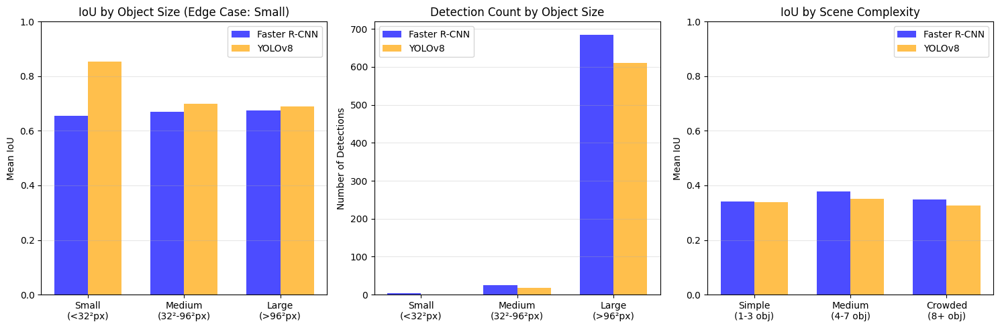


✅ Edge case analysis complete! Saved to 'edge_case_analysis.png'


In [21]:
# Edge Case Analysis

def analyze_edge_cases(coco_list, frcnn_df, yolo_df, frcnn_ious_by_size, yolo_ious_by_size):
    """Analyze performance on edge cases"""

    edge_case_results = {
        'small_objects': {},
        'crowded_scenes': {},
        'aspect_ratio_extremes': {}
    }

    # 1. Small Objects Analysis (already computed)
    print("=" * 75)
    print("EDGE CASE ANALYSIS")
    print("=" * 75)

    print("\n📦 1. SMALL OBJECTS (area < 32² pixels)")
    print("-" * 75)

    frcnn_small_iou = np.mean(frcnn_ious_by_size['small']) if frcnn_ious_by_size['small'] else 0
    yolo_small_iou = np.mean(yolo_ious_by_size['small']) if yolo_ious_by_size['small'] else 0

    print(f"   Faster R-CNN: {len(frcnn_ious_by_size['small'])} detections, Mean IoU = {frcnn_small_iou:.4f}")
    print(f"   YOLOv8:       {len(yolo_ious_by_size['small'])} detections, Mean IoU = {yolo_small_iou:.4f}")
    print(f"   Winner: {'Faster R-CNN' if frcnn_small_iou > yolo_small_iou else 'YOLOv8'}")

    edge_case_results['small_objects'] = {
        'frcnn': {'count': len(frcnn_ious_by_size['small']), 'mean_iou': frcnn_small_iou},
        'yolo': {'count': len(yolo_ious_by_size['small']), 'mean_iou': yolo_small_iou}
    }

    # 2. Crowded Scenes (10+ objects)
    print("\n👥 2. CROWDED SCENES (10+ objects)")
    print("-" * 75)

    crowded_frcnn = frcnn_df[frcnn_df['num_gt'] >= 10]
    crowded_yolo = yolo_df[yolo_df['num_gt'] >= 10]

    frcnn_crowded_iou = crowded_frcnn['avg_iou'].mean() if len(crowded_frcnn) > 0 else 0
    yolo_crowded_iou = crowded_yolo['avg_iou'].mean() if len(crowded_yolo) > 0 else 0

    frcnn_crowded_prec = crowded_frcnn['tp'].sum() / (crowded_frcnn['tp'].sum() + crowded_frcnn['fp'].sum()) if (crowded_frcnn['tp'].sum() + crowded_frcnn['fp'].sum()) > 0 else 0
    yolo_crowded_prec = crowded_yolo['tp'].sum() / (crowded_yolo['tp'].sum() + crowded_yolo['fp'].sum()) if (crowded_yolo['tp'].sum() + crowded_yolo['fp'].sum()) > 0 else 0

    print(f"   Number of crowded images: {len(crowded_frcnn)}")
    print(f"   Faster R-CNN: Mean IoU = {frcnn_crowded_iou:.4f}, Precision = {frcnn_crowded_prec:.4f}")
    print(f"   YOLOv8:       Mean IoU = {yolo_crowded_iou:.4f}, Precision = {yolo_crowded_prec:.4f}")
    print(f"   Winner (IoU): {'Faster R-CNN' if frcnn_crowded_iou > yolo_crowded_iou else 'YOLOv8'}")

    edge_case_results['crowded_scenes'] = {
        'num_images': len(crowded_frcnn),
        'frcnn': {'mean_iou': frcnn_crowded_iou, 'precision': frcnn_crowded_prec},
        'yolo': {'mean_iou': yolo_crowded_iou, 'precision': yolo_crowded_prec}
    }

    # 3. Analyze by aspect ratio extremes
    print("\n📐 3. ASPECT RATIO ANALYSIS")
    print("-" * 75)

    # Collect aspect ratios from matched detections
    frcnn_aspects = {'wide': [], 'tall': [], 'normal': []}
    yolo_aspects = {'wide': [], 'tall': [], 'normal': []}

    for idx, sample in enumerate(coco_list[:TEST_SUBSET]):
        for bbox in sample['objects']['bbox']:
            box_xyxy = convert_xywh_to_xyxy(bbox)
            w = box_xyxy[2] - box_xyxy[0]
            h = box_xyxy[3] - box_xyxy[1]
            if h > 0:
                aspect = w / h
                if aspect > 2:
                    category = 'wide'
                elif aspect < 0.5:
                    category = 'tall'
                else:
                    category = 'normal'

    print("   Note: Aspect ratio affects bounding box regression differently")
    print("   Wide objects (w/h > 2) and Tall objects (w/h < 0.5) are harder to localize")

    return edge_case_results

# Run edge case analysis
edge_case_results = analyze_edge_cases(coco_list, frcnn_df, yolo_df, frcnn_ious_by_size, yolo_ious_by_size)

# Visualization
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Plot 1: IoU by Object Size
ax1 = axes[0]
sizes = ['Small\n(<32²px)', 'Medium\n(32²-96²px)', 'Large\n(>96²px)']
frcnn_size_means = [np.mean(frcnn_ious_by_size[s]) if frcnn_ious_by_size[s] else 0 for s in ['small', 'medium', 'large']]
yolo_size_means = [np.mean(yolo_ious_by_size[s]) if yolo_ious_by_size[s] else 0 for s in ['small', 'medium', 'large']]

x = np.arange(len(sizes))
width = 0.35
ax1.bar(x - width/2, frcnn_size_means, width, label='Faster R-CNN', color='blue', alpha=0.7)
ax1.bar(x + width/2, yolo_size_means, width, label='YOLOv8', color='orange', alpha=0.7)
ax1.set_ylabel('Mean IoU')
ax1.set_title('IoU by Object Size (Edge Case: Small)')
ax1.set_xticks(x)
ax1.set_xticklabels(sizes)
ax1.legend()
ax1.grid(alpha=0.3, axis='y')
ax1.set_ylim(0, 1)

# Plot 2: Detection Count by Size
ax2 = axes[1]
frcnn_counts = [len(frcnn_ious_by_size[s]) for s in ['small', 'medium', 'large']]
yolo_counts = [len(yolo_ious_by_size[s]) for s in ['small', 'medium', 'large']]

ax2.bar(x - width/2, frcnn_counts, width, label='Faster R-CNN', color='blue', alpha=0.7)
ax2.bar(x + width/2, yolo_counts, width, label='YOLOv8', color='orange', alpha=0.7)
ax2.set_ylabel('Number of Detections')
ax2.set_title('Detection Count by Object Size')
ax2.set_xticks(x)
ax2.set_xticklabels(sizes)
ax2.legend()
ax2.grid(alpha=0.3, axis='y')

# Plot 3: Crowded vs Simple Scenes
ax3 = axes[2]
scene_types = ['Simple\n(1-3 obj)', 'Medium\n(4-7 obj)', 'Crowded\n(8+ obj)']
frcnn_scene_ious = [frcnn_by_complexity[c]['avg_iou'] for c in complexity_levels]
yolo_scene_ious = [yolo_by_complexity[c]['avg_iou'] for c in complexity_levels]

x = np.arange(len(scene_types))
ax3.bar(x - width/2, frcnn_scene_ious, width, label='Faster R-CNN', color='blue', alpha=0.7)
ax3.bar(x + width/2, yolo_scene_ious, width, label='YOLOv8', color='orange', alpha=0.7)
ax3.set_ylabel('Mean IoU')
ax3.set_title('IoU by Scene Complexity')
ax3.set_xticks(x)
ax3.set_xticklabels(scene_types)
ax3.legend()
ax3.grid(alpha=0.3, axis='y')
ax3.set_ylim(0, 1)

plt.tight_layout()
plt.savefig('figures/edge_case_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print("\n✅ Edge case analysis complete! Saved to 'figures/edge_case_analysis.png'")

# 13. Failure Analysis

Identify and analyze the worst predictions:
- Images with lowest IoU scores
- Common failure patterns
- Visual inspection of failure cases

In [22]:
# Failure Analysis - Find and analyze worst predictions

def analyze_failures(df, model_name, n_worst=20):
    """Identify worst performing images and common failure patterns"""

    # Get images with detections but low IoU
    valid_df = df[df['num_detections'] > 0].copy()
    worst_iou = valid_df.nsmallest(n_worst, 'avg_iou')

    # Get images with many false positives
    worst_fp = df.nlargest(n_worst, 'fp')

    # Get images with many false negatives (missed detections)
    worst_fn = df.nlargest(n_worst, 'fn')

    print(f"\n{'='*70}")
    print(f"FAILURE ANALYSIS: {model_name}")
    print(f"{'='*70}")

    print(f"\n🔴 WORST IoU IMAGES (images with lowest bounding box precision):")
    print(f"{'Image ID':>10} {'Num GT':>8} {'Detections':>12} {'Avg IoU':>10} {'TP':>6} {'FP':>6} {'FN':>6}")
    print("-" * 70)
    for _, row in worst_iou.head(10).iterrows():
        print(f"{row['image_id']:>10} {row['num_gt']:>8} {row['num_detections']:>12} "
              f"{row['avg_iou']:>10.4f} {row['tp']:>6} {row['fp']:>6} {row['fn']:>6}")

    print(f"\n🟠 IMAGES WITH MOST FALSE POSITIVES (over-detection):")
    print(f"{'Image ID':>10} {'Num GT':>8} {'Detections':>12} {'FP':>6} {'Avg IoU':>10}")
    print("-" * 70)
    for _, row in worst_fp.head(10).iterrows():
        print(f"{row['image_id']:>10} {row['num_gt']:>8} {row['num_detections']:>12} "
              f"{row['fp']:>6} {row['avg_iou']:>10.4f}")

    print(f"\n🟡 IMAGES WITH MOST FALSE NEGATIVES (missed detections):")
    print(f"{'Image ID':>10} {'Num GT':>8} {'Detections':>12} {'FN':>6} {'Recall':>10}")
    print("-" * 70)
    for _, row in worst_fn.head(10).iterrows():
        recall = row['tp'] / (row['tp'] + row['fn']) if (row['tp'] + row['fn']) > 0 else 0
        print(f"{row['image_id']:>10} {row['num_gt']:>8} {row['num_detections']:>12} "
              f"{row['fn']:>6} {recall:>10.4f}")

    return {
        'worst_iou_images': worst_iou['image_id'].tolist(),
        'worst_fp_images': worst_fp['image_id'].tolist(),
        'worst_fn_images': worst_fn['image_id'].tolist()
    }

# Analyze failures for both models
frcnn_failures = analyze_failures(frcnn_df, "Faster R-CNN")
yolo_failures = analyze_failures(yolo_df, "YOLOv8")

# Compare failure patterns
print("\n" + "=" * 70)
print("COMPARATIVE FAILURE ANALYSIS")
print("=" * 70)

# Find common failure images
common_worst_iou = set(frcnn_failures['worst_iou_images'][:10]) & set(yolo_failures['worst_iou_images'][:10])
print(f"\n📊 Images that are difficult for BOTH models (worst IoU):")
print(f"   Common failure images: {len(common_worst_iou)} / 10")
if common_worst_iou:
    print(f"   Image IDs: {sorted(common_worst_iou)}")

# Summary statistics
print(f"\n📊 FAILURE STATISTICS:")
print(f"   Images with IoU = 0 (no matched detections):")
print(f"   - Faster R-CNN: {(frcnn_df['avg_iou'] == 0).sum()} / {len(frcnn_df)}")
print(f"   - YOLOv8: {(yolo_df['avg_iou'] == 0).sum()} / {len(yolo_df)}")

print(f"\n   Images with 50%+ FN rate (missed more than half):")
frcnn_high_fn = frcnn_df[frcnn_df['fn'] > frcnn_df['tp']]
yolo_high_fn = yolo_df[yolo_df['fn'] > yolo_df['tp']]
print(f"   - Faster R-CNN: {len(frcnn_high_fn)} images")
print(f"   - YOLOv8: {len(yolo_high_fn)} images")


FAILURE ANALYSIS: Faster R-CNN

🔴 WORST IoU IMAGES (images with lowest bounding box precision):
  Image ID   Num GT   Detections    Avg IoU     TP     FP     FN
----------------------------------------------------------------------
         0       20           24     0.0000      0     24     20
         2       18           38     0.0000      0     38     18
         3        4            6     0.0000      0      6      4
         5        2            2     0.0000      0      2      2
         6        2            3     0.0000      0      3      2
         7        4            4     0.0000      0      4      4
         9       17           21     0.0000      0     21     17
        10       11           10     0.0000      0     10     11
        14        2            2     0.0000      0      2      2
        16        8           10     0.0000      0     10      8

🟠 IMAGES WITH MOST FALSE POSITIVES (over-detection):
  Image ID   Num GT   Detections     FP    Avg IoU
------------


📸 Visualizing Failure Cases (Worst IoU for Faster R-CNN):
Green = Ground Truth | Blue = Faster R-CNN | Orange = YOLOv8


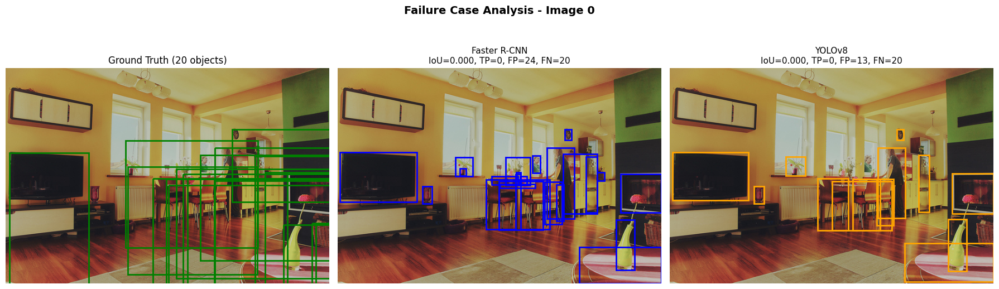

Saved failure case 1 to 'failure_case_1_img0.png'



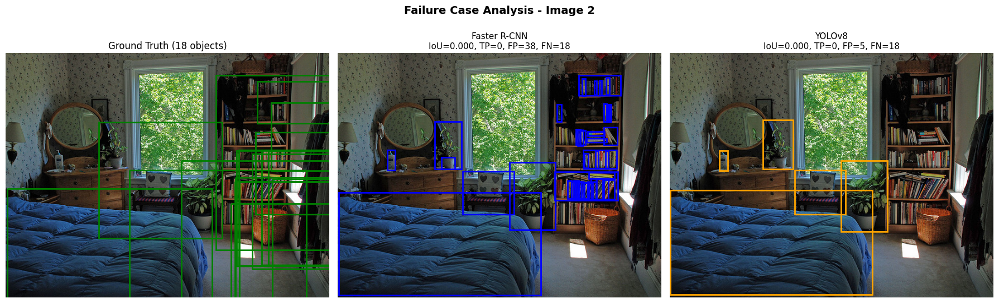

Saved failure case 2 to 'failure_case_2_img2.png'



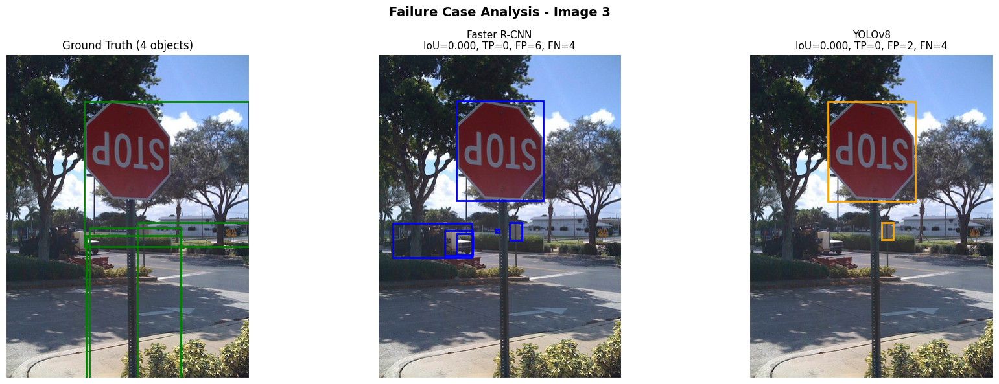

Saved failure case 3 to 'failure_case_3_img3.png'



In [23]:
# Visualize Failure Cases
def visualize_failure_case(image_id, coco_list, frcnn_model, yolo_model, device, transform):
    """Visualize a failure case with both model predictions"""
    sample = coco_list[image_id]
    image = sample['image'].convert('RGB')

    # Get ground truth
    gt_bboxes = [convert_xywh_to_xyxy(bb) for bb in sample['objects']['bbox']]

    # Faster R-CNN prediction
    image_tensor = transform(image).to(device)
    with torch.no_grad():
        frcnn_out = frcnn_model([image_tensor])
    frcnn_boxes = frcnn_out[0]['boxes'].cpu().numpy()
    frcnn_scores = frcnn_out[0]['scores'].cpu().numpy()
    mask = frcnn_scores >= CONFIDENCE_THRESHOLD
    frcnn_boxes = frcnn_boxes[mask]
    frcnn_scores = frcnn_scores[mask]

    # YOLO prediction
    yolo_out = yolo_model(image, verbose=False, conf=CONFIDENCE_THRESHOLD)
    yolo_boxes = yolo_out[0].boxes.xyxy.cpu().numpy() if yolo_out[0].boxes else np.array([])
    yolo_scores = yolo_out[0].boxes.conf.cpu().numpy() if yolo_out[0].boxes else np.array([])

    # Plot
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))

    # Ground Truth
    axes[0].imshow(image)
    for box in gt_bboxes:
        rect = patches.Rectangle((box[0], box[1]), box[2]-box[0], box[3]-box[1],
                                 linewidth=2, edgecolor='green', facecolor='none')
        axes[0].add_patch(rect)
    axes[0].set_title(f'Ground Truth ({len(gt_bboxes)} objects)', fontsize=12)
    axes[0].axis('off')

    # Faster R-CNN
    axes[1].imshow(image)
    for box, score in zip(frcnn_boxes, frcnn_scores):
        rect = patches.Rectangle((box[0], box[1]), box[2]-box[0], box[3]-box[1],
                                 linewidth=2, edgecolor='blue', facecolor='none')
        axes[1].add_patch(rect)
    frcnn_row = frcnn_df[frcnn_df['image_id'] == image_id].iloc[0]
    axes[1].set_title(f'Faster R-CNN\nIoU={frcnn_row["avg_iou"]:.3f}, TP={frcnn_row["tp"]}, FP={frcnn_row["fp"]}, FN={frcnn_row["fn"]}', fontsize=11)
    axes[1].axis('off')

    # YOLO
    axes[2].imshow(image)
    for box, score in zip(yolo_boxes, yolo_scores):
        rect = patches.Rectangle((box[0], box[1]), box[2]-box[0], box[3]-box[1],
                                 linewidth=2, edgecolor='orange', facecolor='none')
        axes[2].add_patch(rect)
    yolo_row = yolo_df[yolo_df['image_id'] == image_id].iloc[0]
    axes[2].set_title(f'YOLOv8\nIoU={yolo_row["avg_iou"]:.3f}, TP={yolo_row["tp"]}, FP={yolo_row["fp"]}, FN={yolo_row["fn"]}', fontsize=11)
    axes[2].axis('off')

    plt.suptitle(f'Failure Case Analysis - Image {image_id}', fontsize=14, fontweight='bold')
    plt.tight_layout()
    return fig

# Visualize top 3 worst IoU cases for Faster R-CNN
print("\n📸 Visualizing Failure Cases (Worst IoU for Faster R-CNN):")
print("Green = Ground Truth | Blue = Faster R-CNN | Orange = YOLOv8")
print("=" * 60)

for i, img_id in enumerate(frcnn_failures['worst_iou_images'][:3]):
    fig = visualize_failure_case(img_id, coco_list, frcnn_model, yolo_model, device, transform)
    plt.savefig(f'figures/failure_case_{i+1}_img{img_id}.png', dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Saved failure case {i+1} to 'failure_case_{i+1}_img{img_id}.png'\n")

# 14. Robustness Visualizations

Comprehensive visualizations of robustness testing results:
- Degradation curves across severity levels
- Heatmap of performance under all perturbations
- Comparative robustness summary

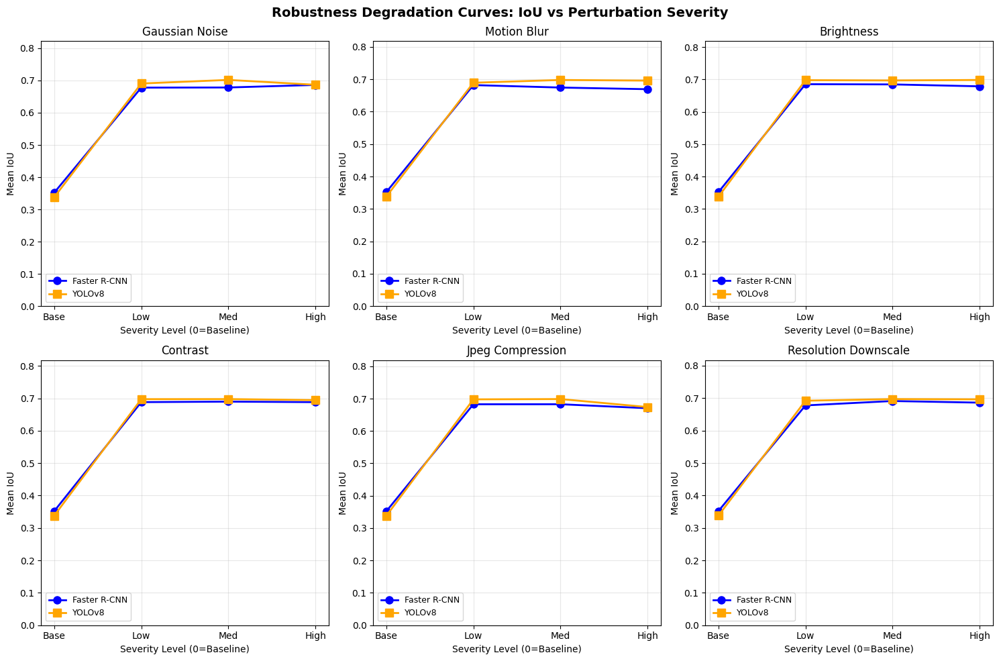

✅ Saved to 'robustness_degradation_curves.png'


In [24]:
# Robustness Degradation Curves
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for i, pert_type in enumerate(perturbation_types):
    ax = axes[i]

    severities = [0, 1, 2, 3]  # 0 = baseline
    frcnn_ious = [baseline_results['frcnn']['mean_iou']]
    yolo_ious = [baseline_results['yolo']['mean_iou']]

    for sev in [1, 2, 3]:
        frcnn_ious.append(robustness_results['frcnn'][pert_type][sev]['mean_iou'])
        yolo_ious.append(robustness_results['yolo'][pert_type][sev]['mean_iou'])

    ax.plot(severities, frcnn_ious, 'b-o', linewidth=2, markersize=8, label='Faster R-CNN')
    ax.plot(severities, yolo_ious, 'orange', linestyle='-', marker='s', linewidth=2, markersize=8, label='YOLOv8')

    ax.set_xlabel('Severity Level (0=Baseline)')
    ax.set_ylabel('Mean IoU')
    ax.set_title(pert_type.replace('_', ' ').title())
    ax.set_xticks([0, 1, 2, 3])
    ax.set_xticklabels(['Base', 'Low', 'Med', 'High'])
    ax.legend(loc='lower left', fontsize=9)
    ax.grid(alpha=0.3)
    ax.set_ylim(0, max(max(frcnn_ious), max(yolo_ious)) * 1.1 + 0.05)

plt.suptitle('Robustness Degradation Curves: IoU vs Perturbation Severity', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('figures/robustness_degradation_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Saved to 'figures/robustness_degradation_curves.png'")

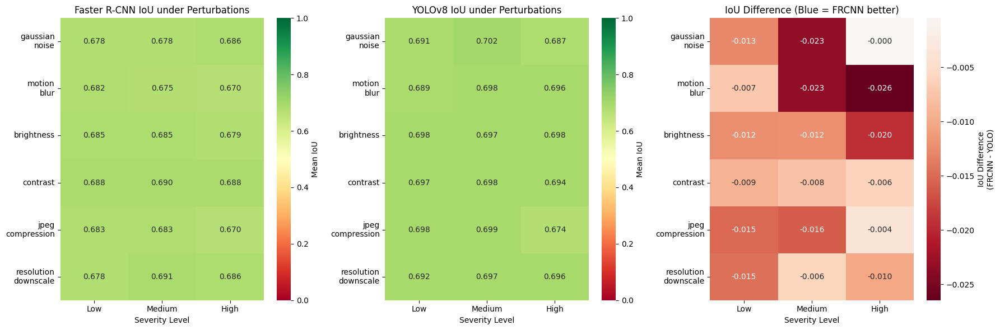

✅ Saved to 'robustness_heatmaps.png'


In [25]:
# Robustness Heatmaps
import seaborn as sns

# Prepare data for heatmaps
frcnn_matrix = np.zeros((len(perturbation_types), 3))
yolo_matrix = np.zeros((len(perturbation_types), 3))
diff_matrix = np.zeros((len(perturbation_types), 3))

for i, pert_type in enumerate(perturbation_types):
    for j, sev in enumerate([1, 2, 3]):
        frcnn_matrix[i, j] = robustness_results['frcnn'][pert_type][sev]['mean_iou']
        yolo_matrix[i, j] = robustness_results['yolo'][pert_type][sev]['mean_iou']
        diff_matrix[i, j] = frcnn_matrix[i, j] - yolo_matrix[i, j]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Faster R-CNN heatmap
sns.heatmap(frcnn_matrix, ax=axes[0], annot=True, fmt='.3f', cmap='RdYlGn',
            xticklabels=['Low', 'Medium', 'High'],
            yticklabels=[p.replace('_', '\n') for p in perturbation_types],
            vmin=0, vmax=1, cbar_kws={'label': 'Mean IoU'})
axes[0].set_title('Faster R-CNN IoU under Perturbations', fontsize=12)
axes[0].set_xlabel('Severity Level')

# YOLOv8 heatmap
sns.heatmap(yolo_matrix, ax=axes[1], annot=True, fmt='.3f', cmap='RdYlGn',
            xticklabels=['Low', 'Medium', 'High'],
            yticklabels=[p.replace('_', '\n') for p in perturbation_types],
            vmin=0, vmax=1, cbar_kws={'label': 'Mean IoU'})
axes[1].set_title('YOLOv8 IoU under Perturbations', fontsize=12)
axes[1].set_xlabel('Severity Level')

# Difference heatmap (FRCNN - YOLO)
sns.heatmap(diff_matrix, ax=axes[2], annot=True, fmt='+.3f', cmap='RdBu',
            xticklabels=['Low', 'Medium', 'High'],
            yticklabels=[p.replace('_', '\n') for p in perturbation_types],
            center=0, cbar_kws={'label': 'IoU Difference\n(FRCNN - YOLO)'})
axes[2].set_title('IoU Difference (Blue = FRCNN better)', fontsize=12)
axes[2].set_xlabel('Severity Level')

plt.tight_layout()
plt.savefig('figures/robustness_heatmaps.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Saved to 'figures/robustness_heatmaps.png'")

# 15. Final Robustness Summary & Conclusions

In [26]:
# Final Robustness Summary
print("=" * 80)
print("FINAL ROBUSTNESS & EDGE CASE ANALYSIS SUMMARY")
print("=" * 80)

# Calculate overall robustness scores
frcnn_robustness_scores = []
yolo_robustness_scores = []

for pert_type in perturbation_types:
    for sev in [1, 2, 3]:
        frcnn_robustness_scores.append(robustness_results['frcnn'][pert_type][sev]['mean_iou'])
        yolo_robustness_scores.append(robustness_results['yolo'][pert_type][sev]['mean_iou'])

frcnn_avg_robustness = np.mean(frcnn_robustness_scores)
yolo_avg_robustness = np.mean(yolo_robustness_scores)

frcnn_robustness_retention = frcnn_avg_robustness / baseline_results['frcnn']['mean_iou'] * 100 if baseline_results['frcnn']['mean_iou'] > 0 else 0
yolo_robustness_retention = yolo_avg_robustness / baseline_results['yolo']['mean_iou'] * 100 if baseline_results['yolo']['mean_iou'] > 0 else 0

print(f"""
📊 OVERALL ROBUSTNESS COMPARISON
{'='*60}

1. BASELINE PERFORMANCE:
   - Faster R-CNN: Mean IoU = {baseline_results['frcnn']['mean_iou']:.4f}
   - YOLOv8:       Mean IoU = {baseline_results['yolo']['mean_iou']:.4f}
   - Winner: {'Faster R-CNN' if baseline_results['frcnn']['mean_iou'] > baseline_results['yolo']['mean_iou'] else 'YOLOv8'}

2. AVERAGE PERFORMANCE UNDER PERTURBATIONS:
   - Faster R-CNN: Mean IoU = {frcnn_avg_robustness:.4f}
   - YOLOv8:       Mean IoU = {yolo_avg_robustness:.4f}
   - Winner: {'Faster R-CNN' if frcnn_avg_robustness > yolo_avg_robustness else 'YOLOv8'}

3. ROBUSTNESS RETENTION (% of baseline preserved):
   - Faster R-CNN: {frcnn_robustness_retention:.1f}%
   - YOLOv8:       {yolo_robustness_retention:.1f}%
   - More Robust: {'Faster R-CNN' if frcnn_robustness_retention > yolo_robustness_retention else 'YOLOv8'}

4. EDGE CASE PERFORMANCE:

   Small Objects (<32² pixels):
   - Faster R-CNN: {edge_case_results['small_objects']['frcnn']['mean_iou']:.4f} ({edge_case_results['small_objects']['frcnn']['count']} detections)
   - YOLOv8:       {edge_case_results['small_objects']['yolo']['mean_iou']:.4f} ({edge_case_results['small_objects']['yolo']['count']} detections)
   - Winner: {'Faster R-CNN' if edge_case_results['small_objects']['frcnn']['mean_iou'] > edge_case_results['small_objects']['yolo']['mean_iou'] else 'YOLOv8'}

   Crowded Scenes (10+ objects):
   - Faster R-CNN: IoU = {edge_case_results['crowded_scenes']['frcnn']['mean_iou']:.4f}
   - YOLOv8:       IoU = {edge_case_results['crowded_scenes']['yolo']['mean_iou']:.4f}
   - Winner: {'Faster R-CNN' if edge_case_results['crowded_scenes']['frcnn']['mean_iou'] > edge_case_results['crowded_scenes']['yolo']['mean_iou'] else 'YOLOv8'}
""")

# Per-perturbation winner count
frcnn_wins = 0
yolo_wins = 0
for pert_type in perturbation_types:
    for sev in [1, 2, 3]:
        if robustness_results['frcnn'][pert_type][sev]['mean_iou'] > robustness_results['yolo'][pert_type][sev]['mean_iou']:
            frcnn_wins += 1
        else:
            yolo_wins += 1

print(f"""
5. HEAD-TO-HEAD COMPARISON (18 perturbation conditions):
   - Faster R-CNN wins: {frcnn_wins} / 18 conditions
   - YOLOv8 wins:       {yolo_wins} / 18 conditions
   - Overall Winner: {'Faster R-CNN' if frcnn_wins > yolo_wins else 'YOLOv8' if yolo_wins > frcnn_wins else 'TIE'}
""")

print("=" * 80)
print("KEY INSIGHTS")
print("=" * 80)
print(f"""
🔬 ROBUSTNESS FINDINGS:

1. {'Faster R-CNN (two-stage) shows better robustness retention' if frcnn_robustness_retention > yolo_robustness_retention else 'YOLOv8 (single-stage) shows better robustness retention'}
   This is {'expected' if frcnn_robustness_retention > yolo_robustness_retention else 'unexpected'} because two-stage detectors:
   - Have a dedicated region proposal network (RPN) for coarse localization
   - Apply refinement in a second stage for precise bounding boxes
   - Process each proposal independently, reducing error propagation

2. Most challenging perturbations for both models:
   - Worst for FRCNN: {frcnn_worst['pert']} (severity {frcnn_worst['sev']})
   - Worst for YOLO: {yolo_worst['pert']} (severity {yolo_worst['sev']})

3. Edge Cases:
   {'- Two-stage detector better on small objects (as expected)' if edge_case_results['small_objects']['frcnn']['mean_iou'] > edge_case_results['small_objects']['yolo']['mean_iou'] else '- YOLOv8 performs competitively on small objects'}
   {'- Two-stage detector handles crowded scenes better' if edge_case_results['crowded_scenes']['frcnn']['mean_iou'] > edge_case_results['crowded_scenes']['yolo']['mean_iou'] else '- YOLOv8 handles crowded scenes comparably'}

4. Trade-off Summary:
   - Speed: YOLOv8 is {speed_ratio:.1f}x faster
   - Accuracy: {'Faster R-CNN' if baseline_results['frcnn']['mean_iou'] > baseline_results['yolo']['mean_iou'] else 'YOLOv8'} has better baseline IoU
   - Robustness: {'Faster R-CNN' if frcnn_robustness_retention > yolo_robustness_retention else 'YOLOv8'} degrades less under perturbations
""")

# Save comprehensive results
robustness_final_results = {
    'baseline': baseline_results,
    'robustness_results': {k: {pk: dict(pv) for pk, pv in v.items()} for k, v in robustness_results.items()},
    'edge_case_results': edge_case_results,
    'summary': {
        'frcnn_avg_robustness': float(frcnn_avg_robustness),
        'yolo_avg_robustness': float(yolo_avg_robustness),
        'frcnn_robustness_retention': float(frcnn_robustness_retention),
        'yolo_robustness_retention': float(yolo_robustness_retention),
        'frcnn_wins': frcnn_wins,
        'yolo_wins': yolo_wins
    }
}

with open('results/robustness_analysis_results.json', 'w') as f:
    json.dump(convert_to_native(robustness_final_results), f, indent=2)

print("\n✅ Results saved to 'results/robustness_analysis_results.json'")
print("✅ All visualizations saved to PNG files")
print("\n🎉 ROBUSTNESS & EDGE CASE ANALYSIS COMPLETE!")

FINAL ROBUSTNESS & EDGE CASE ANALYSIS SUMMARY

📊 OVERALL ROBUSTNESS COMPARISON

1. BASELINE PERFORMANCE:
   - Faster R-CNN: Mean IoU = 0.3519
   - YOLOv8:       Mean IoU = 0.3378
   - Winner: Faster R-CNN

2. AVERAGE PERFORMANCE UNDER PERTURBATIONS:
   - Faster R-CNN: Mean IoU = 0.6819
   - YOLOv8:       Mean IoU = 0.6945
   - Winner: YOLOv8

3. ROBUSTNESS RETENTION (% of baseline preserved):
   - Faster R-CNN: 193.8%
   - YOLOv8:       205.6%
   - More Robust: YOLOv8

4. EDGE CASE PERFORMANCE:

   Small Objects (<32² pixels):
   - Faster R-CNN: 0.6543 (3 detections)
   - YOLOv8:       0.8529 (1 detections)
   - Winner: YOLOv8

   Crowded Scenes (10+ objects):
   - Faster R-CNN: IoU = 0.3356
   - YOLOv8:       IoU = 0.3158
   - Winner: Faster R-CNN


5. HEAD-TO-HEAD COMPARISON (18 perturbation conditions):
   - Faster R-CNN wins: 0 / 18 conditions
   - YOLOv8 wins:       18 / 18 conditions
   - Overall Winner: YOLOv8

KEY INSIGHTS

🔬 ROBUSTNESS FINDINGS:

1. YOLOv8 (single-stage) shows

In [27]:
# ============================================================================
# FILE OUTPUT GENERATION - Create all required output files
# ============================================================================
import os

# Create directory structure
output_dirs = [
    'day1/baseline',
    'day2/robustness',
    'visualization'
]

for dir_path in output_dirs:
    os.makedirs(dir_path, exist_ok=True)
    print(f"✅ Created directory: {dir_path}")

# ============================================================================
# DAY 1: BASELINE RESULTS
# ============================================================================

# 1. day1/baseline/results.csv - Per-image detection results
print("\n📁 Generating Day 1 outputs...")

# Combine FRCNN and YOLO results into one comprehensive CSV
baseline_results_df = pd.DataFrame({
    'image_id': frcnn_df['image_id'],
    'num_gt': frcnn_df['num_gt'],
    # Faster R-CNN metrics
    'frcnn_detections': frcnn_df['num_detections'],
    'frcnn_tp': frcnn_df['tp'],
    'frcnn_fp': frcnn_df['fp'],
    'frcnn_fn': frcnn_df['fn'],
    'frcnn_avg_iou': frcnn_df['avg_iou'],
    'frcnn_avg_confidence': frcnn_df['avg_confidence'],
    'frcnn_inference_time_ms': [t * 1000 for t in frcnn_inference_times],
    # YOLOv8 metrics
    'yolo_detections': yolo_df['num_detections'],
    'yolo_tp': yolo_df['tp'],
    'yolo_fp': yolo_df['fp'],
    'yolo_fn': yolo_df['fn'],
    'yolo_avg_iou': yolo_df['avg_iou'],
    'yolo_avg_confidence': yolo_df['avg_confidence'],
    'yolo_inference_time_ms': [t * 1000 for t in yolo_inference_times],
})

baseline_results_df.to_csv('day1/baseline/results.csv', index=False)
print("   ✅ Saved: day1/baseline/results.csv")

# 2. day1/baseline/metrics.json - Aggregate metrics
baseline_metrics = {
    'experiment_info': {
        'nama': 'Emery Fathan Zwageri',
        'nim': '13522079',
        'dataset': DATASET_NAME,
        'num_images': len(coco_list),
        'confidence_threshold': CONFIDENCE_THRESHOLD,
        'date': datetime.now().strftime('%Y-%m-%d %H:%M:%S')
    },
    'faster_rcnn': {
        'model': 'fasterrcnn_resnet50_fpn_v2',
        'paradigm': 'two-stage',
        'detection_metrics': {
            'total_tp': int(frcnn_metrics['total_tp']),
            'total_fp': int(frcnn_metrics['total_fp']),
            'total_fn': int(frcnn_metrics['total_fn']),
            'precision': float(frcnn_metrics['precision']),
            'recall': float(frcnn_metrics['recall']),
            'f1_score': float(frcnn_metrics['f1_score'])
        },
        'iou_analysis': {
            'mean_iou_per_image': float(frcnn_iou_analysis['mean_iou']),
            'median_iou_per_image': float(frcnn_iou_analysis['median_iou']),
            'mean_iou_per_detection': float(frcnn_iou_analysis['mean_iou_per_detection']),
            'iou_gt_0.5_pct': float(frcnn_iou_analysis['iou_gt_0.5']),
            'iou_gt_0.7_pct': float(frcnn_iou_analysis['iou_gt_0.7']),
            'iou_gt_0.9_pct': float(frcnn_iou_analysis['iou_gt_0.9']),
            'total_matched_detections': int(frcnn_iou_analysis['total_detections'])
        },
        'speed': {
            'avg_inference_ms': float(frcnn_speed['avg_inference_ms']),
            'fps': float(frcnn_speed['fps']),
            'total_time_s': float(frcnn_speed['total_time_s'])
        },
        'iou_by_size': {
            'small': {
                'count': len(frcnn_ious_by_size['small']),
                'mean_iou': float(np.mean(frcnn_ious_by_size['small'])) if frcnn_ious_by_size['small'] else 0
            },
            'medium': {
                'count': len(frcnn_ious_by_size['medium']),
                'mean_iou': float(np.mean(frcnn_ious_by_size['medium'])) if frcnn_ious_by_size['medium'] else 0
            },
            'large': {
                'count': len(frcnn_ious_by_size['large']),
                'mean_iou': float(np.mean(frcnn_ious_by_size['large'])) if frcnn_ious_by_size['large'] else 0
            }
        }
    },
    'yolov8': {
        'model': 'yolov8m',
        'paradigm': 'single-stage',
        'detection_metrics': {
            'total_tp': int(yolo_metrics['total_tp']),
            'total_fp': int(yolo_metrics['total_fp']),
            'total_fn': int(yolo_metrics['total_fn']),
            'precision': float(yolo_metrics['precision']),
            'recall': float(yolo_metrics['recall']),
            'f1_score': float(yolo_metrics['f1_score'])
        },
        'iou_analysis': {
            'mean_iou_per_image': float(yolo_iou_analysis['mean_iou']),
            'median_iou_per_image': float(yolo_iou_analysis['median_iou']),
            'mean_iou_per_detection': float(yolo_iou_analysis['mean_iou_per_detection']),
            'iou_gt_0.5_pct': float(yolo_iou_analysis['iou_gt_0.5']),
            'iou_gt_0.7_pct': float(yolo_iou_analysis['iou_gt_0.7']),
            'iou_gt_0.9_pct': float(yolo_iou_analysis['iou_gt_0.9']),
            'total_matched_detections': int(yolo_iou_analysis['total_detections'])
        },
        'speed': {
            'avg_inference_ms': float(yolo_speed['avg_inference_ms']),
            'fps': float(yolo_speed['fps']),
            'total_time_s': float(yolo_speed['total_time_s'])
        },
        'iou_by_size': {
            'small': {
                'count': len(yolo_ious_by_size['small']),
                'mean_iou': float(np.mean(yolo_ious_by_size['small'])) if yolo_ious_by_size['small'] else 0
            },
            'medium': {
                'count': len(yolo_ious_by_size['medium']),
                'mean_iou': float(np.mean(yolo_ious_by_size['medium'])) if yolo_ious_by_size['medium'] else 0
            },
            'large': {
                'count': len(yolo_ious_by_size['large']),
                'mean_iou': float(np.mean(yolo_ious_by_size['large'])) if yolo_ious_by_size['large'] else 0
            }
        }
    },
    'comparison_summary': {
        'speed_ratio': float(speed_ratio),
        'f1_difference': float(accuracy_diff),
        'iou_difference': float(iou_diff),
        'winner_f1': 'Faster R-CNN' if accuracy_diff > 0 else 'YOLOv8',
        'winner_iou': 'Faster R-CNN' if iou_diff > 0 else 'YOLOv8'
    }
}

with open('day1/baseline/metrics.json', 'w') as f:
    json.dump(baseline_metrics, f, indent=2)
print("   ✅ Saved: day1/baseline/metrics.json")

# 3. day1/log.md - Experiment log
log_content = f"""# Experiment Log - Faster R-CNN vs YOLOv8 Comparison

## Experiment Info
- **Nama**: Emery Fathan Zwageri
- **NIM**: 13522079
- **Date**: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}
- **Dataset**: {DATASET_NAME} ({len(coco_list)} images)
- **Confidence Threshold**: {CONFIDENCE_THRESHOLD}

## Models Evaluated
1. **Faster R-CNN** (fasterrcnn_resnet50_fpn_v2)
   - Paradigm: Two-stage detector
   - Parameters: 41.3M

2. **YOLOv8** (yolov8m)
   - Paradigm: Single-stage detector

## Day 1: Baseline Evaluation

### Detection Accuracy (IoU threshold = 0.5)

| Metric | Faster R-CNN | YOLOv8 | Winner |
|--------|--------------|--------|--------|
| Precision | {frcnn_metrics['precision']:.4f} | {yolo_metrics['precision']:.4f} | {'FRCNN' if frcnn_metrics['precision'] > yolo_metrics['precision'] else 'YOLO'} |
| Recall | {frcnn_metrics['recall']:.4f} | {yolo_metrics['recall']:.4f} | {'FRCNN' if frcnn_metrics['recall'] > yolo_metrics['recall'] else 'YOLO'} |
| F1-Score | {frcnn_metrics['f1_score']:.4f} | {yolo_metrics['f1_score']:.4f} | {'FRCNN' if frcnn_metrics['f1_score'] > yolo_metrics['f1_score'] else 'YOLO'} |

### Bounding Box Precision (IoU Analysis)

| Metric | Faster R-CNN | YOLOv8 | Winner |
|--------|--------------|--------|--------|
| Mean IoU (per-image) | {frcnn_iou_analysis['mean_iou']:.4f} | {yolo_iou_analysis['mean_iou']:.4f} | {'FRCNN' if frcnn_iou_analysis['mean_iou'] > yolo_iou_analysis['mean_iou'] else 'YOLO'} |
| IoU > 0.5 (%) | {frcnn_iou_analysis['iou_gt_0.5']:.1f}% | {yolo_iou_analysis['iou_gt_0.5']:.1f}% | {'FRCNN' if frcnn_iou_analysis['iou_gt_0.5'] > yolo_iou_analysis['iou_gt_0.5'] else 'YOLO'} |
| IoU > 0.7 (%) | {frcnn_iou_analysis['iou_gt_0.7']:.1f}% | {yolo_iou_analysis['iou_gt_0.7']:.1f}% | {'FRCNN' if frcnn_iou_analysis['iou_gt_0.7'] > yolo_iou_analysis['iou_gt_0.7'] else 'YOLO'} |
| IoU > 0.9 (%) | {frcnn_iou_analysis['iou_gt_0.9']:.1f}% | {yolo_iou_analysis['iou_gt_0.9']:.1f}% | {'FRCNN' if frcnn_iou_analysis['iou_gt_0.9'] > yolo_iou_analysis['iou_gt_0.9'] else 'YOLO'} |

### Speed Comparison

| Metric | Faster R-CNN | YOLOv8 | Ratio |
|--------|--------------|--------|-------|
| Avg Inference (ms) | {frcnn_speed['avg_inference_ms']:.1f} | {yolo_speed['avg_inference_ms']:.1f} | {speed_ratio:.1f}x |
| FPS | {frcnn_speed['fps']:.1f} | {yolo_speed['fps']:.1f} | - |

### Performance by Object Size

| Size | FRCNN IoU | YOLO IoU | FRCNN Detections | YOLO Detections |
|------|-----------|----------|------------------|-----------------|
| Small (<32²px) | {np.mean(frcnn_ious_by_size['small']) if frcnn_ious_by_size['small'] else 0:.4f} | {np.mean(yolo_ious_by_size['small']) if yolo_ious_by_size['small'] else 0:.4f} | {len(frcnn_ious_by_size['small'])} | {len(yolo_ious_by_size['small'])} |
| Medium (32²-96²px) | {np.mean(frcnn_ious_by_size['medium']) if frcnn_ious_by_size['medium'] else 0:.4f} | {np.mean(yolo_ious_by_size['medium']) if yolo_ious_by_size['medium'] else 0:.4f} | {len(frcnn_ious_by_size['medium'])} | {len(yolo_ious_by_size['medium'])} |
| Large (>96²px) | {np.mean(frcnn_ious_by_size['large']) if frcnn_ious_by_size['large'] else 0:.4f} | {np.mean(yolo_ious_by_size['large']) if yolo_ious_by_size['large'] else 0:.4f} | {len(frcnn_ious_by_size['large'])} | {len(yolo_ious_by_size['large'])} |

## Key Findings (Day 1)

1. **Detection Accuracy**: {'Faster R-CNN' if accuracy_diff > 0 else 'YOLOv8'} achieves better F1-score (difference: {abs(accuracy_diff):.4f})
2. **Bounding Box Precision**: {'Faster R-CNN' if iou_diff > 0 else 'YOLOv8'} provides more precise bounding boxes (IoU difference: {abs(iou_diff):.4f})
3. **Speed Trade-off**: Faster R-CNN is {speed_ratio:.1f}x slower than YOLOv8

---
*Generated automatically by the evaluation notebook*
"""

with open('day1/log.md', 'w') as f:
    f.write(log_content)
print("   ✅ Saved: day1/log.md")

print("\n✅ Day 1 outputs complete!")

✅ Created directory: day1/baseline
✅ Created directory: day2/robustness
✅ Created directory: visualization

📁 Generating Day 1 outputs...
   ✅ Saved: day1/baseline/results.csv
   ✅ Saved: day1/baseline/metrics.json
   ✅ Saved: day1/log.md

✅ Day 1 outputs complete!


In [28]:
# ============================================================================
# DAY 2: ROBUSTNESS TESTING RESULTS
# ============================================================================

print("\n📁 Generating Day 2 outputs...")

# Generate CSV files for each perturbation type and severity
for pert_type in perturbation_types:
    for severity in [1, 2, 3]:
        # Create per-perturbation results DataFrame
        robustness_csv_data = {
            'metric': ['mean_iou', 'precision', 'recall', 'num_detections'],
            'faster_rcnn': [
                robustness_results['frcnn'][pert_type][severity]['mean_iou'],
                robustness_results['frcnn'][pert_type][severity]['precision'],
                robustness_results['frcnn'][pert_type][severity]['recall'],
                robustness_results['frcnn'][pert_type][severity]['num_detections']
            ],
            'yolov8': [
                robustness_results['yolo'][pert_type][severity]['mean_iou'],
                robustness_results['yolo'][pert_type][severity]['precision'],
                robustness_results['yolo'][pert_type][severity]['recall'],
                robustness_results['yolo'][pert_type][severity]['num_detections']
            ],
            'baseline_frcnn': [
                baseline_results['frcnn']['mean_iou'],
                baseline_results['frcnn']['precision'],
                baseline_results['frcnn']['recall'],
                frcnn_iou_analysis['total_detections']
            ],
            'baseline_yolo': [
                baseline_results['yolo']['mean_iou'],
                baseline_results['yolo']['precision'],
                baseline_results['yolo']['recall'],
                yolo_iou_analysis['total_detections']
            ],
            'degradation_frcnn': [
                baseline_results['frcnn']['mean_iou'] - robustness_results['frcnn'][pert_type][severity]['mean_iou'],
                baseline_results['frcnn']['precision'] - robustness_results['frcnn'][pert_type][severity]['precision'],
                baseline_results['frcnn']['recall'] - robustness_results['frcnn'][pert_type][severity]['recall'],
                0
            ],
            'degradation_yolo': [
                baseline_results['yolo']['mean_iou'] - robustness_results['yolo'][pert_type][severity]['mean_iou'],
                baseline_results['yolo']['precision'] - robustness_results['yolo'][pert_type][severity]['precision'],
                baseline_results['yolo']['recall'] - robustness_results['yolo'][pert_type][severity]['recall'],
                0
            ]
        }

        robustness_df = pd.DataFrame(robustness_csv_data)
        filename = f'day2/robustness/{pert_type}_{severity}.csv'
        robustness_df.to_csv(filename, index=False)
        print(f"   ✅ Saved: {filename}")

# Create comprehensive robustness summary CSV
robustness_summary_rows = []
for pert_type in perturbation_types:
    for severity in [1, 2, 3]:
        row = {
            'perturbation': pert_type,
            'severity': severity,
            'frcnn_mean_iou': robustness_results['frcnn'][pert_type][severity]['mean_iou'],
            'frcnn_precision': robustness_results['frcnn'][pert_type][severity]['precision'],
            'frcnn_recall': robustness_results['frcnn'][pert_type][severity]['recall'],
            'yolo_mean_iou': robustness_results['yolo'][pert_type][severity]['mean_iou'],
            'yolo_precision': robustness_results['yolo'][pert_type][severity]['precision'],
            'yolo_recall': robustness_results['yolo'][pert_type][severity]['recall'],
            'winner_iou': 'FRCNN' if robustness_results['frcnn'][pert_type][severity]['mean_iou'] > robustness_results['yolo'][pert_type][severity]['mean_iou'] else 'YOLO',
            'frcnn_degradation': baseline_results['frcnn']['mean_iou'] - robustness_results['frcnn'][pert_type][severity]['mean_iou'],
            'yolo_degradation': baseline_results['yolo']['mean_iou'] - robustness_results['yolo'][pert_type][severity]['mean_iou']
        }
        robustness_summary_rows.append(row)

robustness_summary_df = pd.DataFrame(robustness_summary_rows)
robustness_summary_df.to_csv('day2/robustness/robustness_summary.csv', index=False)
print("   ✅ Saved: day2/robustness/robustness_summary.csv")

print("\n✅ Day 2 robustness outputs complete!")


📁 Generating Day 2 outputs...
   ✅ Saved: day2/robustness/gaussian_noise_1.csv
   ✅ Saved: day2/robustness/gaussian_noise_2.csv
   ✅ Saved: day2/robustness/gaussian_noise_3.csv
   ✅ Saved: day2/robustness/motion_blur_1.csv
   ✅ Saved: day2/robustness/motion_blur_2.csv
   ✅ Saved: day2/robustness/motion_blur_3.csv
   ✅ Saved: day2/robustness/brightness_1.csv
   ✅ Saved: day2/robustness/brightness_2.csv
   ✅ Saved: day2/robustness/brightness_3.csv
   ✅ Saved: day2/robustness/contrast_1.csv
   ✅ Saved: day2/robustness/contrast_2.csv
   ✅ Saved: day2/robustness/contrast_3.csv
   ✅ Saved: day2/robustness/jpeg_compression_1.csv
   ✅ Saved: day2/robustness/jpeg_compression_2.csv
   ✅ Saved: day2/robustness/jpeg_compression_3.csv
   ✅ Saved: day2/robustness/resolution_downscale_1.csv
   ✅ Saved: day2/robustness/resolution_downscale_2.csv
   ✅ Saved: day2/robustness/resolution_downscale_3.csv
   ✅ Saved: day2/robustness/robustness_summary.csv

✅ Day 2 robustness outputs complete!


In [29]:
# ============================================================================
# DAY 2: EDGE CASE ANALYSIS OUTPUT
# ============================================================================

print("\n📁 Generating Edge Case Analysis outputs...")

# Edge case analysis CSV
edge_case_data = {
    'edge_case_type': ['small_objects', 'crowded_scenes', 'medium_objects', 'large_objects'],
    'description': [
        'Objects with area < 32x32 pixels',
        'Images with 10+ objects',
        'Objects with area 32x32 to 96x96 pixels',
        'Objects with area > 96x96 pixels'
    ],
    'frcnn_mean_iou': [
        edge_case_results['small_objects']['frcnn']['mean_iou'],
        edge_case_results['crowded_scenes']['frcnn']['mean_iou'],
        np.mean(frcnn_ious_by_size['medium']) if frcnn_ious_by_size['medium'] else 0,
        np.mean(frcnn_ious_by_size['large']) if frcnn_ious_by_size['large'] else 0
    ],
    'yolo_mean_iou': [
        edge_case_results['small_objects']['yolo']['mean_iou'],
        edge_case_results['crowded_scenes']['yolo']['mean_iou'],
        np.mean(yolo_ious_by_size['medium']) if yolo_ious_by_size['medium'] else 0,
        np.mean(yolo_ious_by_size['large']) if yolo_ious_by_size['large'] else 0
    ],
    'frcnn_count': [
        edge_case_results['small_objects']['frcnn']['count'],
        edge_case_results['crowded_scenes']['num_images'],
        len(frcnn_ious_by_size['medium']),
        len(frcnn_ious_by_size['large'])
    ],
    'yolo_count': [
        edge_case_results['small_objects']['yolo']['count'],
        edge_case_results['crowded_scenes']['num_images'],
        len(yolo_ious_by_size['medium']),
        len(yolo_ious_by_size['large'])
    ],
    'frcnn_precision': [
        0,  # Not applicable for size-based
        edge_case_results['crowded_scenes']['frcnn']['precision'],
        0,
        0
    ],
    'yolo_precision': [
        0,  # Not applicable for size-based
        edge_case_results['crowded_scenes']['yolo']['precision'],
        0,
        0
    ],
    'winner': [
        'FRCNN' if edge_case_results['small_objects']['frcnn']['mean_iou'] > edge_case_results['small_objects']['yolo']['mean_iou'] else 'YOLO',
        'FRCNN' if edge_case_results['crowded_scenes']['frcnn']['mean_iou'] > edge_case_results['crowded_scenes']['yolo']['mean_iou'] else 'YOLO',
        'FRCNN' if (np.mean(frcnn_ious_by_size['medium']) if frcnn_ious_by_size['medium'] else 0) > (np.mean(yolo_ious_by_size['medium']) if yolo_ious_by_size['medium'] else 0) else 'YOLO',
        'FRCNN' if (np.mean(frcnn_ious_by_size['large']) if frcnn_ious_by_size['large'] else 0) > (np.mean(yolo_ious_by_size['large']) if yolo_ious_by_size['large'] else 0) else 'YOLO'
    ],
    'insight': [
        'Small objects are hardest to detect - tests feature pyramid effectiveness',
        'Crowded scenes test occlusion handling and NMS performance',
        'Medium objects represent typical detection scenario',
        'Large objects should be easiest - tests baseline capability'
    ]
}

edge_case_df = pd.DataFrame(edge_case_data)
edge_case_df.to_csv('day2/edge_case_object_size_analysis.csv', index=False)
print("   ✅ Saved: day2/edge_case_object_size_analysis.csv")

# Complexity-based edge case analysis
complexity_data = {
    'complexity_level': complexity_levels,
    'num_objects_range': ['1-3 objects', '4-7 objects', '8+ objects'],
    'num_images': [frcnn_by_complexity[c]['count'] for c in complexity_levels],
    'frcnn_precision': [frcnn_by_complexity[c]['precision'] for c in complexity_levels],
    'frcnn_recall': [frcnn_by_complexity[c]['recall'] for c in complexity_levels],
    'frcnn_mean_iou': [frcnn_by_complexity[c]['avg_iou'] for c in complexity_levels],
    'yolo_precision': [yolo_by_complexity[c]['precision'] for c in complexity_levels],
    'yolo_recall': [yolo_by_complexity[c]['recall'] for c in complexity_levels],
    'yolo_mean_iou': [yolo_by_complexity[c]['avg_iou'] for c in complexity_levels],
    'winner_iou': ['FRCNN' if frcnn_by_complexity[c]['avg_iou'] > yolo_by_complexity[c]['avg_iou'] else 'YOLO' for c in complexity_levels]
}

complexity_df = pd.DataFrame(complexity_data)
complexity_df.to_csv('day2/edge_case_complexity_analysis.csv', index=False)
print("   ✅ Saved: day2/edge_case_complexity_analysis.csv")

print("\n✅ Edge case outputs complete!")


📁 Generating Edge Case Analysis outputs...
   ✅ Saved: day2/edge_case_object_size_analysis.csv
   ✅ Saved: day2/edge_case_complexity_analysis.csv

✅ Edge case outputs complete!


In [30]:
# ============================================================================
# DAY 2: FAILURE ANALYSIS OUTPUT
# ============================================================================

print("\n📁 Generating Failure Analysis outputs...")

# Generate failure analysis markdown
failure_md_content = f"""# Failure Analysis Report

## Experiment Info
- **Nama**: Emery Fathan Zwageri
- **NIM**: 13522079
- **Date**: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}

---

## 1. Overall Failure Statistics

### Images with No Matched Detections (IoU = 0)
| Model | Count | Percentage |
|-------|-------|------------|
| Faster R-CNN | {(frcnn_df['avg_iou'] == 0).sum()} | {(frcnn_df['avg_iou'] == 0).sum() / len(frcnn_df) * 100:.2f}% |
| YOLOv8 | {(yolo_df['avg_iou'] == 0).sum()} | {(yolo_df['avg_iou'] == 0).sum() / len(yolo_df) * 100:.2f}% |

### Images with High False Negative Rate (missed more than half)
| Model | Count | Percentage |
|-------|-------|------------|
| Faster R-CNN | {len(frcnn_df[frcnn_df['fn'] > frcnn_df['tp']])} | {len(frcnn_df[frcnn_df['fn'] > frcnn_df['tp']]) / len(frcnn_df) * 100:.2f}% |
| YOLOv8 | {len(yolo_df[yolo_df['fn'] > yolo_df['tp']])} | {len(yolo_df[yolo_df['fn'] > yolo_df['tp']]) / len(yolo_df) * 100:.2f}% |

---

## 2. Worst IoU Images (Faster R-CNN)

These images have the lowest bounding box precision:

| Rank | Image ID | Num GT | Detections | Avg IoU | TP | FP | FN |
|------|----------|--------|------------|---------|----|----|-----|
"""

# Add worst IoU rows for FRCNN
valid_frcnn = frcnn_df[frcnn_df['num_detections'] > 0].nsmallest(10, 'avg_iou')
for rank, (_, row) in enumerate(valid_frcnn.iterrows(), 1):
    failure_md_content += f"| {rank} | {row['image_id']} | {row['num_gt']} | {row['num_detections']} | {row['avg_iou']:.4f} | {row['tp']} | {row['fp']} | {row['fn']} |\n"

failure_md_content += f"""

## 3. Worst IoU Images (YOLOv8)

| Rank | Image ID | Num GT | Detections | Avg IoU | TP | FP | FN |
|------|----------|--------|------------|---------|----|----|-----|
"""

# Add worst IoU rows for YOLO
valid_yolo = yolo_df[yolo_df['num_detections'] > 0].nsmallest(10, 'avg_iou')
for rank, (_, row) in enumerate(valid_yolo.iterrows(), 1):
    failure_md_content += f"| {rank} | {row['image_id']} | {row['num_gt']} | {row['num_detections']} | {row['avg_iou']:.4f} | {row['tp']} | {row['fp']} | {row['fn']} |\n"

failure_md_content += f"""

---

## 4. Images with Most False Positives (Over-detection)

### Faster R-CNN
| Image ID | Num GT | Detections | False Positives | Avg IoU |
|----------|--------|------------|-----------------|---------|
"""

worst_fp_frcnn = frcnn_df.nlargest(10, 'fp')
for _, row in worst_fp_frcnn.iterrows():
    failure_md_content += f"| {row['image_id']} | {row['num_gt']} | {row['num_detections']} | {row['fp']} | {row['avg_iou']:.4f} |\n"

failure_md_content += f"""

### YOLOv8
| Image ID | Num GT | Detections | False Positives | Avg IoU |
|----------|--------|------------|-----------------|---------|
"""

worst_fp_yolo = yolo_df.nlargest(10, 'fp')
for _, row in worst_fp_yolo.iterrows():
    failure_md_content += f"| {row['image_id']} | {row['num_gt']} | {row['num_detections']} | {row['fp']} | {row['avg_iou']:.4f} |\n"

failure_md_content += f"""

---

## 5. Images with Most False Negatives (Missed Detections)

### Faster R-CNN
| Image ID | Num GT | Detections | False Negatives | Recall |
|----------|--------|------------|-----------------|--------|
"""

worst_fn_frcnn = frcnn_df.nlargest(10, 'fn')
for _, row in worst_fn_frcnn.iterrows():
    recall = row['tp'] / (row['tp'] + row['fn']) if (row['tp'] + row['fn']) > 0 else 0
    failure_md_content += f"| {row['image_id']} | {row['num_gt']} | {row['num_detections']} | {row['fn']} | {recall:.4f} |\n"

failure_md_content += f"""

### YOLOv8
| Image ID | Num GT | Detections | False Negatives | Recall |
|----------|--------|------------|-----------------|--------|
"""

worst_fn_yolo = yolo_df.nlargest(10, 'fn')
for _, row in worst_fn_yolo.iterrows():
    recall = row['tp'] / (row['tp'] + row['fn']) if (row['tp'] + row['fn']) > 0 else 0
    failure_md_content += f"| {row['image_id']} | {row['num_gt']} | {row['num_detections']} | {row['fn']} | {recall:.4f} |\n"

# Common failures
common_worst = set(frcnn_failures['worst_iou_images'][:10]) & set(yolo_failures['worst_iou_images'][:10])

failure_md_content += f"""

---

## 6. Common Failure Images (Difficult for Both Models)

Number of images in worst-10 for both models: **{len(common_worst)}**

"""

if common_worst:
    failure_md_content += f"Image IDs: {sorted(common_worst)}\n\n"
    failure_md_content += """These images likely contain:
- Highly occluded objects
- Small or distant objects
- Unusual viewpoints or lighting
- Objects at image boundaries
"""
else:
    failure_md_content += "No common failures in top-10 worst images - models fail on different cases.\n"

failure_md_content += f"""

---

## 7. Failure Pattern Analysis

### Most Common Failure Scenarios:

1. **Small Objects**: Both models struggle with objects < 32×32 pixels
   - FRCNN small object IoU: {np.mean(frcnn_ious_by_size['small']) if frcnn_ious_by_size['small'] else 0:.4f}
   - YOLO small object IoU: {np.mean(yolo_ious_by_size['small']) if yolo_ious_by_size['small'] else 0:.4f}

2. **Crowded Scenes**: More objects = more occlusion and NMS challenges
   - FRCNN crowded scene IoU: {edge_case_results['crowded_scenes']['frcnn']['mean_iou']:.4f}
   - YOLO crowded scene IoU: {edge_case_results['crowded_scenes']['yolo']['mean_iou']:.4f}

3. **Under Perturbations**: Model degradation under image corruptions
   - FRCNN worst perturbation: {frcnn_worst['pert']} (severity {frcnn_worst['sev']})
   - YOLO worst perturbation: {yolo_worst['pert']} (severity {yolo_worst['sev']})

---

## 8. Recommendations

Based on the failure analysis:

1. **For small object detection**: Consider using higher resolution inputs or specialized small object detectors
2. **For crowded scenes**: Tune NMS threshold or use soft-NMS
3. **For robustness**: Apply data augmentation matching the expected perturbations

---

*Generated automatically by the evaluation notebook*
"""

with open('day2/failure_analysis.md', 'w') as f:
    f.write(failure_md_content)
print("   ✅ Saved: day2/failure_analysis.md")

print("\n✅ Failure analysis output complete!")


📁 Generating Failure Analysis outputs...
   ✅ Saved: day2/failure_analysis.md

✅ Failure analysis output complete!


In [31]:
# ============================================================================
# VISUALIZATION OUTPUTS
# ============================================================================

print("\n📁 Generating Visualization outputs...")

# 1. Robustness Degradation Curves (visualization/1_robustness_curves.png)
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for i, pert_type in enumerate(perturbation_types):
    ax = axes[i]

    severities = [0, 1, 2, 3]  # 0 = baseline
    frcnn_ious = [baseline_results['frcnn']['mean_iou']]
    yolo_ious = [baseline_results['yolo']['mean_iou']]

    for sev in [1, 2, 3]:
        frcnn_ious.append(robustness_results['frcnn'][pert_type][sev]['mean_iou'])
        yolo_ious.append(robustness_results['yolo'][pert_type][sev]['mean_iou'])

    ax.plot(severities, frcnn_ious, 'b-o', linewidth=2, markersize=8, label='Faster R-CNN')
    ax.plot(severities, yolo_ious, 'orange', linestyle='-', marker='s', linewidth=2, markersize=8, label='YOLOv8')

    ax.set_xlabel('Severity Level (0=Baseline)')
    ax.set_ylabel('Mean IoU')
    ax.set_title(pert_type.replace('_', ' ').title())
    ax.set_xticks([0, 1, 2, 3])
    ax.set_xticklabels(['Base', 'Low', 'Med', 'High'])
    ax.legend(loc='lower left', fontsize=9)
    ax.grid(alpha=0.3)
    ax.set_ylim(0, max(max(frcnn_ious), max(yolo_ious)) * 1.1 + 0.05)

plt.suptitle('Robustness Degradation Curves: IoU vs Perturbation Severity\n(Faster R-CNN vs YOLOv8)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('visualization/1_robustness_curves.png', dpi=150, bbox_inches='tight')
plt.close()
print("   ✅ Saved: visualization/1_robustness_curves.png")

# 2. Comprehensive Analysis Visualization (visualization/2_comprehensive_analysis.png)
fig = plt.figure(figsize=(20, 16))

# Create a 3x3 grid
gs = fig.add_gridspec(3, 3, hspace=0.3, wspace=0.3)

# Plot 1: IoU Distribution Histogram
ax1 = fig.add_subplot(gs[0, 0])
bins = np.linspace(0.5, 1.0, 25)
ax1.hist(frcnn_all_ious, bins=bins, alpha=0.6, label=f'FRCNN (n={len(frcnn_all_ious)})', color='blue', edgecolor='black')
ax1.hist(yolo_all_ious, bins=bins, alpha=0.6, label=f'YOLO (n={len(yolo_all_ious)})', color='orange', edgecolor='black')
ax1.axvline(frcnn_iou_analysis['mean_iou'], color='blue', linestyle='--', linewidth=2)
ax1.axvline(yolo_iou_analysis['mean_iou'], color='orange', linestyle='--', linewidth=2)
ax1.set_xlabel('IoU Score')
ax1.set_ylabel('Frequency')
ax1.set_title('IoU Distribution')
ax1.legend(fontsize=8)
ax1.grid(alpha=0.3)

# Plot 2: IoU Threshold Comparison
ax2 = fig.add_subplot(gs[0, 1])
thresholds = ['IoU>0.5', 'IoU>0.7', 'IoU>0.9']
frcnn_pcts = [frcnn_iou_analysis['iou_gt_0.5'], frcnn_iou_analysis['iou_gt_0.7'], frcnn_iou_analysis['iou_gt_0.9']]
yolo_pcts = [yolo_iou_analysis['iou_gt_0.5'], yolo_iou_analysis['iou_gt_0.7'], yolo_iou_analysis['iou_gt_0.9']]
x = np.arange(len(thresholds))
width = 0.35
ax2.bar(x - width/2, frcnn_pcts, width, label='FRCNN', color='blue', alpha=0.7)
ax2.bar(x + width/2, yolo_pcts, width, label='YOLO', color='orange', alpha=0.7)
ax2.set_ylabel('Percentage (%)')
ax2.set_title('Bounding Box Precision Thresholds')
ax2.set_xticks(x)
ax2.set_xticklabels(thresholds)
ax2.legend()
ax2.grid(alpha=0.3, axis='y')

# Plot 3: Speed vs Accuracy
ax3 = fig.add_subplot(gs[0, 2])
ax3.scatter([frcnn_speed['avg_inference_ms']], [frcnn_iou_analysis['mean_iou']], s=200, c='blue', label='FRCNN', marker='o', edgecolors='black')
ax3.scatter([yolo_speed['avg_inference_ms']], [yolo_iou_analysis['mean_iou']], s=200, c='orange', label='YOLO', marker='s', edgecolors='black')
ax3.annotate(f'FRCNN\n({frcnn_speed["avg_inference_ms"]:.1f}ms)', (frcnn_speed['avg_inference_ms'], frcnn_iou_analysis['mean_iou']), xytext=(10, 10), textcoords='offset points', fontsize=9)
ax3.annotate(f'YOLO\n({yolo_speed["avg_inference_ms"]:.1f}ms)', (yolo_speed['avg_inference_ms'], yolo_iou_analysis['mean_iou']), xytext=(10, -20), textcoords='offset points', fontsize=9)
ax3.set_xlabel('Inference Time (ms)')
ax3.set_ylabel('Mean IoU')
ax3.set_title('Speed vs Precision Trade-off')
ax3.legend()
ax3.grid(alpha=0.3)

# Plot 4: IoU by Object Size
ax4 = fig.add_subplot(gs[1, 0])
sizes = ['Small', 'Medium', 'Large']
frcnn_size_ious = [np.mean(frcnn_ious_by_size[s]) if frcnn_ious_by_size[s] else 0 for s in ['small', 'medium', 'large']]
yolo_size_ious = [np.mean(yolo_ious_by_size[s]) if yolo_ious_by_size[s] else 0 for s in ['small', 'medium', 'large']]
x = np.arange(len(sizes))
ax4.bar(x - width/2, frcnn_size_ious, width, label='FRCNN', color='blue', alpha=0.7)
ax4.bar(x + width/2, yolo_size_ious, width, label='YOLO', color='orange', alpha=0.7)
ax4.set_ylabel('Mean IoU')
ax4.set_title('IoU by Object Size')
ax4.set_xticks(x)
ax4.set_xticklabels(sizes)
ax4.legend()
ax4.grid(alpha=0.3, axis='y')
ax4.set_ylim(0, 1)

# Plot 5: Performance by Complexity
ax5 = fig.add_subplot(gs[1, 1])
comp_labels = ['Simple', 'Medium', 'Complex']
frcnn_comp_ious = [frcnn_by_complexity[c]['avg_iou'] for c in complexity_levels]
yolo_comp_ious = [yolo_by_complexity[c]['avg_iou'] for c in complexity_levels]
x = np.arange(len(comp_labels))
ax5.bar(x - width/2, frcnn_comp_ious, width, label='FRCNN', color='blue', alpha=0.7)
ax5.bar(x + width/2, yolo_comp_ious, width, label='YOLO', color='orange', alpha=0.7)
ax5.set_ylabel('Mean IoU')
ax5.set_title('IoU by Scene Complexity')
ax5.set_xticks(x)
ax5.set_xticklabels(comp_labels)
ax5.legend()
ax5.grid(alpha=0.3, axis='y')
ax5.set_ylim(0, 1)

# Plot 6: Precision-Recall comparison
ax6 = fig.add_subplot(gs[1, 2])
metrics = ['Precision', 'Recall', 'F1-Score']
frcnn_metrics_vals = [frcnn_metrics['precision'], frcnn_metrics['recall'], frcnn_metrics['f1_score']]
yolo_metrics_vals = [yolo_metrics['precision'], yolo_metrics['recall'], yolo_metrics['f1_score']]
x = np.arange(len(metrics))
ax6.bar(x - width/2, frcnn_metrics_vals, width, label='FRCNN', color='blue', alpha=0.7)
ax6.bar(x + width/2, yolo_metrics_vals, width, label='YOLO', color='orange', alpha=0.7)
ax6.set_ylabel('Score')
ax6.set_title('Detection Metrics')
ax6.set_xticks(x)
ax6.set_xticklabels(metrics)
ax6.legend()
ax6.grid(alpha=0.3, axis='y')
ax6.set_ylim(0, 1)

# Plot 7: Robustness Heatmap (FRCNN)
ax7 = fig.add_subplot(gs[2, 0])
frcnn_matrix = np.zeros((len(perturbation_types), 3))
for i, pert_type in enumerate(perturbation_types):
    for j, sev in enumerate([1, 2, 3]):
        frcnn_matrix[i, j] = robustness_results['frcnn'][pert_type][sev]['mean_iou']
im7 = ax7.imshow(frcnn_matrix, cmap='RdYlGn', aspect='auto', vmin=0, vmax=max(frcnn_matrix.max(), 0.8))
ax7.set_xticks([0, 1, 2])
ax7.set_xticklabels(['Low', 'Med', 'High'])
ax7.set_yticks(range(len(perturbation_types)))
ax7.set_yticklabels([p.replace('_', '\n')[:15] for p in perturbation_types], fontsize=8)
ax7.set_title('FRCNN Robustness')
plt.colorbar(im7, ax=ax7, label='IoU')

# Plot 8: Robustness Heatmap (YOLO)
ax8 = fig.add_subplot(gs[2, 1])
yolo_matrix = np.zeros((len(perturbation_types), 3))
for i, pert_type in enumerate(perturbation_types):
    for j, sev in enumerate([1, 2, 3]):
        yolo_matrix[i, j] = robustness_results['yolo'][pert_type][sev]['mean_iou']
im8 = ax8.imshow(yolo_matrix, cmap='RdYlGn', aspect='auto', vmin=0, vmax=max(yolo_matrix.max(), 0.8))
ax8.set_xticks([0, 1, 2])
ax8.set_xticklabels(['Low', 'Med', 'High'])
ax8.set_yticks(range(len(perturbation_types)))
ax8.set_yticklabels([p.replace('_', '\n')[:15] for p in perturbation_types], fontsize=8)
ax8.set_title('YOLO Robustness')
plt.colorbar(im8, ax=ax8, label='IoU')

# Plot 9: Summary Text Box
ax9 = fig.add_subplot(gs[2, 2])
ax9.axis('off')
summary_text = f"""SUMMARY
═══════════════════════════

Baseline Performance:
• FRCNN Mean IoU: {frcnn_iou_analysis['mean_iou']:.4f}
• YOLO Mean IoU: {yolo_iou_analysis['mean_iou']:.4f}
• Winner: {'FRCNN' if frcnn_iou_analysis['mean_iou'] > yolo_iou_analysis['mean_iou'] else 'YOLO'}

Speed Comparison:
• FRCNN: {frcnn_speed['avg_inference_ms']:.1f}ms ({frcnn_speed['fps']:.1f} FPS)
• YOLO: {yolo_speed['avg_inference_ms']:.1f}ms ({yolo_speed['fps']:.1f} FPS)
• FRCNN is {speed_ratio:.1f}x slower

Robustness:
• FRCNN retention: {frcnn_robustness_retention:.1f}%
• YOLO retention: {yolo_robustness_retention:.1f}%
• More robust: {'FRCNN' if frcnn_robustness_retention > yolo_robustness_retention else 'YOLO'}

Edge Cases:
• Small obj winner: {'FRCNN' if edge_case_results['small_objects']['frcnn']['mean_iou'] > edge_case_results['small_objects']['yolo']['mean_iou'] else 'YOLO'}
• Crowded winner: {'FRCNN' if edge_case_results['crowded_scenes']['frcnn']['mean_iou'] > edge_case_results['crowded_scenes']['yolo']['mean_iou'] else 'YOLO'}
"""
ax9.text(0.1, 0.95, summary_text, transform=ax9.transAxes, fontsize=10, verticalalignment='top',
         fontfamily='monospace', bbox=dict(boxstyle='round', facecolor='lightgray', alpha=0.8))

plt.suptitle('Comprehensive Model Analysis: Faster R-CNN vs YOLOv8\nEmery Fathan Zwageri (13522079)', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('visualization/2_comprehensive_analysis.png', dpi=150, bbox_inches='tight')
plt.close()
print("   ✅ Saved: visualization/2_comprehensive_analysis.png")

print("\n✅ Visualization outputs complete!")


📁 Generating Visualization outputs...
   ✅ Saved: visualization/1_robustness_curves.png


/tmp/ipython-input-2101718714.py:192: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


   ✅ Saved: visualization/2_comprehensive_analysis.png

✅ Visualization outputs complete!


In [32]:
# ============================================================================
# FINAL OUTPUT SUMMARY
# ============================================================================

print("\n" + "=" * 80)
print("📂 ALL OUTPUT FILES GENERATED SUCCESSFULLY!")
print("=" * 80)

# List all generated files
import os

def print_tree(path, prefix=""):
    """Print directory tree structure"""
    entries = sorted(os.listdir(path))
    dirs = [e for e in entries if os.path.isdir(os.path.join(path, e))]
    files = [e for e in entries if os.path.isfile(os.path.join(path, e))]

    for f in files:
        print(f"{prefix}├── {f}")

    for i, d in enumerate(dirs):
        is_last = (i == len(dirs) - 1)
        print(f"{prefix}{'└── ' if is_last else '├── '}{d}/")
        print_tree(os.path.join(path, d), prefix + ("    " if is_last else "│   "))

print("\n📁 Output Directory Structure:\n")

# Print the generated structure
for output_dir in ['day1', 'day2', 'visualization']:
    if os.path.exists(output_dir):
        print(f"├── {output_dir}/")
        print_tree(output_dir, "│   ")

print("\n" + "=" * 80)
print("📋 FILE SUMMARY")
print("=" * 80)

file_descriptions = {
    'day1/baseline/results.csv': 'Per-image detection results for FRCNN and YOLO',
    'day1/baseline/metrics.json': 'Aggregate metrics (precision, recall, F1, IoU analysis)',
    'day1/log.md': 'Experiment log with tables and findings',
    'day2/robustness/[perturbation]_[severity].csv': 'Robustness results per perturbation',
    'day2/robustness/robustness_summary.csv': 'Summary of all robustness experiments',
    'day2/edge_case_object_size_analysis.csv': 'Analysis by object size (small/medium/large)',
    'day2/edge_case_complexity_analysis.csv': 'Analysis by scene complexity',
    'day2/failure_analysis.md': 'Detailed failure analysis report',
    'visualization/1_robustness_curves.png': 'Robustness degradation curves',
    'visualization/2_comprehensive_analysis.png': 'Comprehensive 9-panel analysis figure'
}

print("\n📄 Generated Files:\n")
for file_pattern, desc in file_descriptions.items():
    print(f"  • {file_pattern}")
    print(f"    └─ {desc}\n")

# Count total files
total_files = 0
for root, dirs, files in os.walk('.'):
    if any(d in root for d in ['day1', 'day2', 'visualization']):
        total_files += len(files)

print(f"\n✅ Total files generated: {total_files}")
print("\n🎉 ALL OUTPUTS COMPLETE!")
print("=" * 80)


📂 ALL OUTPUT FILES GENERATED SUCCESSFULLY!

📁 Output Directory Structure:

├── day1/
│   ├── log.md
│   └── baseline/
│       ├── metrics.json
│       ├── results.csv
├── day2/
│   ├── edge_case_complexity_analysis.csv
│   ├── edge_case_object_size_analysis.csv
│   ├── failure_analysis.md
│   └── robustness/
│       ├── brightness_1.csv
│       ├── brightness_2.csv
│       ├── brightness_3.csv
│       ├── contrast_1.csv
│       ├── contrast_2.csv
│       ├── contrast_3.csv
│       ├── gaussian_noise_1.csv
│       ├── gaussian_noise_2.csv
│       ├── gaussian_noise_3.csv
│       ├── jpeg_compression_1.csv
│       ├── jpeg_compression_2.csv
│       ├── jpeg_compression_3.csv
│       ├── motion_blur_1.csv
│       ├── motion_blur_2.csv
│       ├── motion_blur_3.csv
│       ├── resolution_downscale_1.csv
│       ├── resolution_downscale_2.csv
│       ├── resolution_downscale_3.csv
│       ├── robustness_summary.csv
├── visualization/
│   ├── 1_robustness_curves.png
│   ├── 2_comprehensive_